# Pandas - The Complete Guide (Zero to Advanced)

## Table of contents

01. [Introduction, Installation & Setup](#01-introduction-installation--setup) - *Beginner*
02. [Series - The 1-D Data Structure](#02-series---the-1-d-data-structure) - *Beginner*
03. [DataFrame - The 2-D Data Structure](#03-dataframe---the-2-d-data-structure) - *Beginner*
04. [Reading & Writing Data (I/O)](#04-reading--writing-data-io) - *Beginner*
05. [Inspecting & Understanding Data](#05-inspecting--understanding-data) - *Beginner*
06. [Selecting, Indexing & Filtering](#06-selecting-indexing--filtering) - *Beginner*
07. [Data Types & Type Conversion](#07-data-types--type-conversion) - *Beginner*
08. [Handling Missing Data](#08-handling-missing-data) - *Beginner*
09. [Data Cleaning: Duplicates, Renaming, Replacing & Outliers](#09-data-cleaning-duplicates-renaming-replacing--outliers) - *Beginner*
10. [Column Operations: assign, apply, map, where, cut](#10-column-operations-assign-apply-map-where-cut) - *Intermediate*
11. [Working with Text Data (.str accessor)](#11-working-with-text-data-str-accessor) - *Intermediate*
12. [Date & Time Series Basics](#12-date--time-series-basics) - *Intermediate*
13. [Sorting, Ranking & Top-N](#13-sorting-ranking--top-n) - *Intermediate*
14. [GroupBy & Aggregation (Split-Apply-Combine)](#14-groupby--aggregation-split-apply-combine) - *Intermediate*
15. [Combining Data: concat, merge, join](#15-combining-data-concat-merge-join) - *Intermediate*
16. [Reshaping: pivot, melt, stack, crosstab, dummies](#16-reshaping-pivot-melt-stack-crosstab-dummies) - *Intermediate*
17. [MultiIndex (Hierarchical Indexing)](#17-multiindex-hierarchical-indexing) - *Advanced*
18. [Window Functions: rolling, expanding, ewm, shift](#18-window-functions-rolling-expanding-ewm-shift) - *Advanced*
19. [Categorical Data](#19-categorical-data) - *Advanced*
20. [Data Visualization with Pandas](#20-data-visualization-with-pandas) - *Intermediate*
21. [Performance & Memory Optimisation](#21-performance--memory-optimisation) - *Advanced*
22. [Advanced Techniques: Method Chaining, pipe, Styler, Copy-on-Write](#22-advanced-techniques-method-chaining-pipe-styler-copy-on-write) - *Advanced*
23. [Mini Project: End-to-End Sales Analysis](#23-mini-project-end-to-end-sales-analysis) - *Project*
24. [Practice Exercises & Interview Questions](#24-practice-exercises--interview-questions) - *Project*


## 1. Pandas 

#### Introduction :
 
Pandas is an open-source Python library providing high-performance, easy-to-use data structures and data analysis tools. It is the backbone of data manipulation and preprocessing in Python.

Its two core structures are the **Series** (1-D labelled array) and the **DataFrame** (2-D labelled table).

Pandas has two data structures: Series (1 dimension) and DataFrame (multidimensional)

## Why Pandas?
- Read/write almost any format (CSV, Excel, JSON, SQL, Parquet...)
- Clean messy data (missing values, duplicates, wrong types)
- Slice, filter, group, join, reshape and summarise data in one line
- Built on NumPy, integrates with Matplotlib, scikit-learn, Seaborn, etc.

## Installation
```bash
pip install pandas numpy matplotlib openpyxl pyarrow
# or with conda
conda install pandas
```
By convention pandas is imported as `pd` and NumPy as `np`.

In [4]:
import pandas as pd
import numpy as np

print("pandas :", pd.__version__)
print("numpy  :", np.__version__)

pandas : 2.3.3
numpy  : 2.0.2


## Display options
Pandas lets you control how data is shown. Options are global, so use `pd.option_context` for temporary changes.

In [13]:
pd.set_option("display.max_columns", 30)   # show more columns
pd.set_option("display.precision", 2)        # decimals shown
pd.set_option("display.width", 120)
print(pd.get_option("display.max_rows"))

60


## The datasets used in this guide
All lessons use three small CSV files from the `data/` folder:

| File | Rows | Description |
|------|------|-------------|
| `employees.csv` | 205 | HR data with missing values, duplicates and messy text |
| `customers.csv` | 50 | Customer master table |
| `sales.csv` | 1000 | Orders for 2024 (dates, products, regions, discounts) |

In [14]:
emp = pd.read_csv("data/employees.csv")
customers = pd.read_csv("data/customers.csv")
sales = pd.read_csv("data/sales.csv")
emp.head()

,emp_id,name,department,city,age,salary,join_date,rating,email
0,1001,Priya Iyer,Finance,Mumbai,52,102500.0,2015-07-30,2.0,priya.iyer@company.com
1,1002,Kavya Patel,Marketing,Delhi,49,69400.0,2016-08-28,3.0,kavya.patel@company.com
2,1003,Rohan Mehta,Sales,Bengaluru,43,83000.0,2022-08-12,3.0,rohan.mehta@company.com
3,1004,Priya Nair,Engineering,Hyderabad,55,30000.0,2019-11-11,4.0,priya.nair@company.com
4,1005,Vikram Sharma,Engineering,NaN,26,49600.0,2016-02-29,5.0,vikram.sharma@company.com


---
# 02 Series - The 1-D Data Structure

`Beginner`

> **Definition.** A **Series** is a one-dimensional labelled array that can hold any data type. It has *values* and an *index* (labels).

A Pandas Series is a one-dimensional array-like object that can hold data of any type (integer, float, string etc...). It is labelled, meaning each element has a unique identifier called an index. Series are a fundamental data structure in Pandas and are commonly used for data manipulation and analysis tasks. They can be created from lists, arrays, dictionaries, and existing Series objects.

## Creating a Series

In [42]:
#  crate a Series from a list
data = [1, 2, 3, 4, 5]
series_from_list = pd.Series(data)
print(series_from_list)
print(type(series_from_list))
print(series_from_list.values)
print(series_from_list[1])
print(series_from_list[3])


# crate a Series from a dictionary
data = {'a': 1, 'b': 2, 'c': 3}
series_from_dict = pd.Series(data)
print(series_from_dict)
print(type(series_from_dict))
print(series_from_dict.values)
print(series_from_dict['b'])


# crate a Series with custom index
data = [1, 2, 3, 4, 5]
index = ['a', 'b', 'c', 'd', 'e']
series_custom_index = pd.Series(data, index=index)
print(series_custom_index)

0    1
1    2
2    3
3    4
4    5
dtype: int64
<class 'pandas.core.series.Series'>
[1 2 3 4 5]
2
4
a    1
b    2
c    3
dtype: int64
<class 'pandas.core.series.Series'>
[1 2 3]
2
a    1
b    2
c    3
d    4
e    5
dtype: int64


In [ ]:


# from a list (default index 0..n-1)
s1 = pd.Series([10, 20, 30, 40])

# with a custom index and a name
s2 = pd.Series([10, 20, 30, 40], index=["a", "b", "c", "d"], name="scores")

# from a dict (keys become the index)
s3 = pd.Series({"x": 1, "y": 2, "z": 3})

# from a scalar (broadcast)
s4 = pd.Series(5, index=["p", "q", "r"])
s2


a    10
b    20
c    30
d    40
Name: scores, dtype: int64

In [9]:
print(s2.index)
print(s2.values)       # NumPy array
print(s2.dtype, s2.shape, s2.size, s2.name)

Index(['a', 'b', 'c', 'd'], dtype='object')
[10 20 30 40]
int64 (4,) 4 scores


## Selecting elements
- Label based: `s["b"]`, `s.loc["b"]`
- Position based: `s.iloc[1]`
- Slices: label slices are **inclusive**, position slices are **exclusive** at the end.

In [10]:
print(s2["b"])
print(s2.loc[["a", "c"]])
print(s2.iloc[1:3])
print(s2["a":"c"])        # inclusive of 'c'

20
a    10
c    30
Name: scores, dtype: int64
b    20
c    30
Name: scores, dtype: int64
a    10
b    20
c    30
Name: scores, dtype: int64


In [36]:
# Second Example of creating a Series
import pandas as pd

# Creating a Series 
# Pass a single list, 1D array, or dictionary
my_series = pd.Series([10, 20, 30], name="Age")


## Vectorised operations and alignment
Operations apply to every element without a loop. When two Series are combined, pandas **aligns on the index**; labels present in only one Series become `NaN`.

In [35]:
print(s2 * 2)
print(s2[s2 > 15])               # boolean filtering
print(s2.mean(), s2.sum(), s2.max())

a = pd.Series([1, 2, 3], index=["a", "b", "c"])
b = pd.Series([10, 20, 30], index=["b", "c", "d"])
print(a + b)                       # a and d become NaN
print(a.add(b, fill_value=0))      # treat missing as 0

a    20
b    40
c    60
d    80
Name: scores, dtype: int64
b    20
c    30
d    40
Name: scores, dtype: int64
25.0 100 40
a     NaN
b    12.0
c    23.0
d     NaN
dtype: float64
a     1.0
b    12.0
c    23.0
d    30.0
dtype: float64


## Useful Series methods

In [9]:
city = emp["city"]
print(city.value_counts().head())       # frequency count
print(city.unique())                    # unique values
print(city.nunique())                   # number of unique values
print(emp["salary"].describe())

city
Mumbai       47
Bengaluru    45
Pune         39
Hyderabad    38
Delhi        29
Name: count, dtype: int64
<ArrowStringArray>
['Mumbai', 'Delhi', 'Bengaluru', 'Hyderabad', nan, 'Pune']
Length: 6, dtype: str
5
count       205.00
mean      73928.78
std       22515.28
min       30000.00
25%       55900.00
50%       74700.00
75%       89000.00
max      131100.00
Name: salary, dtype: float64


---
# 03 DataFrame - The 2-D Data Structure

`Beginner`

> **Definition.** A **DataFrame** is a two-dimensional, size-mutable, labelled table with columns of (possibly) different types. Each column is a Series; all columns share the same row index.

## Creating DataFrames

In [125]:
# 1. dict of lists (keys = column names)
df = pd.DataFrame({
    "name": ["Naresh", "Kumar", "Devi", "adi"],
    "age": [25, 30, 35, 28],
    "city": ["Bangalore", "Madanapalle", "Chennai", "Hyderabad"],
})


# 2. list of dicts (each dict = one row)
df2 = pd.DataFrame([{"a": 1, "b": 2}, {"a": 3, "b": 4}])

# 3. NumPy array + labels
df3 = pd.DataFrame(np.arange(12).reshape(4, 3), columns=["x", "y", "z"], index=list("abcd"))

# 4. date-indexed random data
df4 = pd.DataFrame(np.random.default_rng(0).normal(size=(5, 3)),
                   index=pd.date_range("2024-01-01", periods=5), columns=list("ABC"))


df



,name,age,city
0,Naresh,25,Bangalore
1,Kumar,30,Madanapalle
2,Devi,35,Chennai
3,adi,28,Hyderabad


In [126]:
print (df.head(3))          # first 3 rows
print (df.tail(2))          # last 2 rows/
print (df.shape)             # (rows, columns)
print (df.columns)           # column names
print (df.index)             # row labels


     name  age         city
0  Naresh   25    Bangalore
1   Kumar   30  Madanapalle
2    Devi   35      Chennai
   name  age       city
2  Devi   35    Chennai
3   adi   28  Hyderabad
(4, 3)
Index(['name', 'age', 'city'], dtype='object')
RangeIndex(start=0, stop=4, step=1)


## Core attributes

In [127]:
print(df.shape)       # (rows, columns)
print(df.columns)
print(df.index)
print(df.dtypes)
print(df.ndim, df.size)
print(df.to_numpy())

(4, 3)
Index(['name', 'age', 'city'], dtype='object')
RangeIndex(start=0, stop=4, step=1)
name    object
age      int64
city    object
dtype: object
2 12
[['Naresh' 25 'Bangalore']
 ['Kumar' 30 'Madanapalle']
 ['Devi' 35 'Chennai']
 ['adi' 28 'Hyderabad']]


## Adding, modifying and removing columns

In [128]:

# Adding a new column
df['Salary'] = [50000, 60000, 70000, 80000]

# Modify an existing column name

df.insert(1, "id", range(101, 105))                      # insert at a position


df["country"]="india"
df = df.drop(columns=["country"])                         # drop (returns a new frame)

df["age_next_year"]=df["age"]+1                           # Rename Column name

df = df.rename(columns={"age_next_year": "age_plus_1"}) 

df

,name,id,age,city,Salary,age_plus_1
0,Naresh,101,25,Bangalore,50000,26
1,Kumar,102,30,Madanapalle,60000,31
2,Devi,103,35,Chennai,70000,36
3,adi,104,28,Hyderabad,80000,29


## Indexing in Dataframe - access to rows,columns 

`DataFrame` provides flexible indexing options, allowing `access to rows, columns, or individual elements` based on `labels or integer positions`.

In [129]:
# Accessing a column
print(df['name'])                       # Selects and extracts the entire column named 'name'   

# Accessing a row by label
print(df.loc[0])                        # .loc[] stands for label-based location

# Accessing a row by label
print(df.loc[1])                        # .loc[] stands for label-based location

# Accessing a row by integer position
print(df.iloc[0])                      # .iloc[] stands for integer location

# Accessing an individual element
print(df.at[0, 'name'])                # .at[] stands for label-based location



0    Naresh
1     Kumar
2      Devi
3       adi
Name: name, dtype: object
name             Naresh
id                  101
age                  25
city          Bangalore
Salary            50000
age_plus_1           26
Name: 0, dtype: object
name                Kumar
id                    102
age                    30
city          Madanapalle
Salary              60000
age_plus_1             31
Name: 1, dtype: object
name             Naresh
id                  101
age                  25
city          Bangalore
Salary            50000
age_plus_1           26
Name: 0, dtype: object
Naresh


In [130]:
df

,name,id,age,city,Salary,age_plus_1
0,Naresh,101,25,Bangalore,50000,26
1,Kumar,102,30,Madanapalle,60000,31
2,Devi,103,35,Chennai,70000,36
3,adi,104,28,Hyderabad,80000,29


## Missing Data Handling

##### DataFrames provide methods for handling missing or NaN values, including dropping or filling missing values.

In [131]:
# --- Add Null values on new column / reqeuired cell----

df["columnwith_null"]=[np.nan,np.nan,np.nan,np.nan]  #creatre with nan data
df.fillna(0)

# modify any city name to nan

df.at[3,'city']=np.nan

# modify any salary to nan

df.at[3,'city']=np.nan

df.loc[70000]=np.nan


# --- How to FIND NaN Values (Before Deleting) --- 

# Check which cells are null (returns True/False for every cell)
print(df.isna())

# Count how many NaN values are in each column
print(df.isna().sum())

df


        name     id    age   city  Salary  age_plus_1  columnwith_null
0      False  False  False  False   False       False             True
1      False  False  False  False   False       False             True
2      False  False  False  False   False       False             True
3      False  False  False   True   False       False             True
70000   True   True   True   True    True        True             True
name               1
id                 1
age                1
city               2
Salary             1
age_plus_1         1
columnwith_null    5
dtype: int64


,name,id,age,city,Salary,age_plus_1,columnwith_null
0,Naresh,101.0,25.0,Bangalore,50000.0,26.0,NaN
1,Kumar,102.0,30.0,Madanapalle,60000.0,31.0,NaN
2,Devi,103.0,35.0,Chennai,70000.0,36.0,NaN
3,adi,104.0,28.0,NaN,80000.0,29.0,NaN
70000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [132]:
df

,name,id,age,city,Salary,age_plus_1,columnwith_null
0,Naresh,101.0,25.0,Bangalore,50000.0,26.0,NaN
1,Kumar,102.0,30.0,Madanapalle,60000.0,31.0,NaN
2,Devi,103.0,35.0,Chennai,70000.0,36.0,NaN
3,adi,104.0,28.0,NaN,80000.0,29.0,NaN
70000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [133]:
df_clean = df.dropna()
df

,name,id,age,city,Salary,age_plus_1,columnwith_null
0,Naresh,101.0,25.0,Bangalore,50000.0,26.0,NaN
1,Kumar,102.0,30.0,Madanapalle,60000.0,31.0,NaN
2,Devi,103.0,35.0,Chennai,70000.0,36.0,NaN
3,adi,104.0,28.0,NaN,80000.0,29.0,NaN
70000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [135]:
# 
df['city'] = df['city'].fillna('Hyderabad')
df

,name,id,age,city,Salary,age_plus_1,columnwith_null
0,Naresh,101.0,25.0,Bangalore,50000.0,26.0,NaN
1,Kumar,102.0,30.0,Madanapalle,60000.0,31.0,NaN
2,Devi,103.0,35.0,Chennai,70000.0,36.0,NaN
3,adi,104.0,28.0,Hyderabad,80000.0,29.0,NaN
70000,NaN,NaN,NaN,Hyderabad,NaN,NaN,NaN


In [147]:
# Fill column with 1 
df["columnwith_null"]=df["columnwith_null"].fillna(2)
df

,name,id,age,city,Salary,age_plus_1,columnwith_null
0,Naresh,101.0,25.0,Bangalore,50000.0,26.0,1.0
1,Kumar,102.0,30.0,Madanapalle,60000.0,31.0,1.0
2,Devi,103.0,35.0,Chennai,70000.0,36.0,1.0
3,adi,104.0,28.0,Hyderabad,80000.0,29.0,1.0
70000,NaN,NaN,NaN,Hyderabad,NaN,NaN,1.0


## Series vs DataFrame
`df["age"]` returns a **Series**, whereas `df[["age"]]` returns a **DataFrame** with one column.

In [ ]:
print(type(df["age"]), type(df[["age"]]))
df.T          # transpose

<class 'pandas.core.series.Series'> <class 'pandas.core.frame.DataFrame'>


,0,1,2,3
name,Naresh,Kumar,Devi,adi
id,101,102,103,104
age,25,30,35,28
city,Bangalore,Madanapalle,Chennai,Hyderabad
age_plus_1,26,31,36,29


---
# 04 Reading & Writing Data (I/O)

`Beginner`

> **Definition.** Pandas provides `read_*` functions to load data into a DataFrame and `to_*` methods to save it, supporting CSV, Excel, JSON, SQL, Parquet, HTML, clipboard and more.

## CSV - the most common format
Important `read_csv` parameters:

| Parameter | Purpose |
|-----------|---------|
| `sep` | delimiter (`,` `;` `\t`) |
| `usecols` | load only some columns |
| `dtype` | force column types |
| `parse_dates` | convert columns to datetime |
| `index_col` | use a column as the index |
| `na_values` | extra strings to treat as NaN |
| `nrows`, `skiprows` | read part of the file |
| `chunksize` | iterate over a huge file in pieces |

In [166]:
df = pd.read_csv("data/employees.csv")
df.head()


,emp_id,name,department,city,age,salary,join_date,rating,email
0,1001,Priya Iyer,Finance,Mumbai,52,102500.0,2015-07-30,2.0,priya.iyer@company.com
1,1002,Kavya Patel,Marketing,Delhi,49,69400.0,2016-08-28,3.0,kavya.patel@company.com
2,1003,Rohan Mehta,Sales,Bengaluru,43,83000.0,2022-08-12,3.0,rohan.mehta@company.com
3,1004,Priya Nair,Engineering,Hyderabad,55,30000.0,2019-11-11,4.0,priya.nair@company.com
4,1005,Vikram Sharma,Engineering,NaN,26,49600.0,2016-02-29,5.0,vikram.sharma@company.com


In [167]:
# info command ( used to get information of data set
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   emp_id      205 non-null    int64  
 1   name        205 non-null    object 
 2   department  205 non-null    object 
 3   city        198 non-null    object 
 4   age         205 non-null    int64  
 5   salary      205 non-null    float64
 6   join_date   205 non-null    object 
 7   rating      188 non-null    float64
 8   email       196 non-null    object 
dtypes: float64(2), int64(2), object(5)
memory usage: 14.5+ KB


### 1. Read specific columns using read_csv
The usecols parameter allows to load only specific columns from a CSV file. This reduces memory usage and processing time by importing only the required data.

In [156]:
df = pd.read_csv(
    "data/employees.csv",
    usecols=["emp_id", "name", "department", "salary", "join_date"]
)
df.head()

# This notation is a highly optimized way to load data using Pandas method arguments. Instead of loading the entire raw file and cleaning it afterward, you are filtering and structuring the data while it is being read

,emp_id,name,department,salary,join_date
0,1001,Priya Iyer,Finance,102500.0,2015-07-30
1,1002,Kavya Patel,Marketing,69400.0,2016-08-28
2,1003,Rohan Mehta,Sales,83000.0,2022-08-12
3,1004,Priya Nair,Engineering,30000.0,2019-11-11
4,1005,Vikram Sharma,Engineering,49600.0,2016-02-29


c

In [163]:
df = pd.read_csv(
    "data/employees.csv",
    usecols=["emp_id", "name", "department", "salary", "join_date"],index_col="name"
)
df.head()


,emp_id,department,salary,join_date
name,,,,
Priya Iyer,1001,Finance,102500.0,2015-07-30
Kavya Patel,1002,Marketing,69400.0,2016-08-28
Rohan Mehta,1003,Sales,83000.0,2022-08-12
Priya Nair,1004,Engineering,30000.0,2019-11-11
Vikram Sharma,1005,Engineering,49600.0,2016-02-29


In [168]:
# info command ( used to get information of data set
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   emp_id      205 non-null    int64  
 1   name        205 non-null    object 
 2   department  205 non-null    object 
 3   city        198 non-null    object 
 4   age         205 non-null    int64  
 5   salary      205 non-null    float64
 6   join_date   205 non-null    object 
 7   rating      188 non-null    float64
 8   email       196 non-null    object 
dtypes: float64(2), int64(2), object(5)
memory usage: 14.5+ KB


#### 2. describe()
- describe method is used to describe about information of numerical columns in dataset
- The statistical information of numerical columns

In [ ]:
df.describe()

,emp_id,age,salary,rating
count,205.00,205.00,205.00,188.00
mean,1100.11,40.87,73928.78,3.39
std,57.88,10.77,22515.28,1.04
min,1001.00,22.00,30000.00,1.00
25%,1050.00,33.00,55900.00,3.00
50%,1100.00,41.00,74700.00,3.00
75%,1150.00,50.00,89000.00,4.00
max,1200.00,59.00,131100.00,5.00


#### 3.Transpose () - columns method & .T transpose - tilted of rows/cols

In [170]:
# .columns method & .T (transpose - tilted of rows/cols

df.columns

df.T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,...,190,191,192,193,194,195,196,197,198,199,200,201,202,203,204
emp_id,1001,1002,1003,1004,1005,1006,1007,1008,1009,1010,1011,1012,1013,1014,1015,...,1191,1192,1193,1194,1195,1196,1197,1198,1199,1200,1059,1041,1035,1103,1185
name,Priya Iyer,Kavya Patel,Rohan Mehta,Priya Nair,Vikram Sharma,Arjun Joshi,Sanjay Iyer,Sanjay Iyer,Arjun Verma,Amit Patel,Arjun Singh,Sneha Joshi,Meera Nair,Rohan Mehta,Arjun Patel,...,Aarav Joshi,Nikhil Gupta,Aarav Verma,Priya Mehta,Ritu Verma,Sanjay Verma,Neha Reddy,Sanjay Mehta,Aarav Verma,Anita Singh,Aarav Verma,Nikhil Patel,Priya Patel,Pooja Gupta,Aarav Iyer
department,Finance,Marketing,Sales,Engineering,Engineering,Engineering,Engineering,HR,Engineering,Sales,HR,Sales,Engineering,Finance,Finance,...,HR,Engineering,Sales,HR,Engineering,Sales,Finance,Engineering,Sales,Sales,Engineering,Finance,Marketing,Sales,Sales
city,Mumbai,Delhi,Bengaluru,Hyderabad,NaN,Pune,NaN,Mumbai,Delhi,Hyderabad,Mumbai,Hyderabad,Pune,Delhi,Pune,...,Delhi,Bengaluru,Mumbai,Bengaluru,Bengaluru,NaN,Bengaluru,Delhi,Hyderabad,Bengaluru,Pune,Delhi,Hyderabad,NaN,Bengaluru
age,52,49,43,55,26,57,54,41,49,41,32,52,31,33,41,...,37,32,28,48,41,46,49,59,52,45,38,48,24,56,37
salary,102500.0,69400.0,83000.0,30000.0,49600.0,68500.0,51400.0,90700.0,118900.0,49100.0,56600.0,80200.0,110400.0,48100.0,80500.0,...,62800.0,46800.0,112000.0,113000.0,104900.0,80600.0,104700.0,75300.0,79500.0,50900.0,68700.0,80300.0,80200.0,71300.0,89000.0
join_date,2015-07-30,2016-08-28,2022-08-12,2019-11-11,2016-02-29,2024-07-03,2017-07-16,2015-01-15,2023-11-09,2015-02-28,2020-04-20,2024-07-07,2020-07-15,2020-08-08,2018-09-20,...,2016-03-23,2015-06-08,2015-01-31,2019-08-13,2015-11-11,2024-03-11,2017-05-06,2021-04-02,2021-06-15,2019-10-01,2017-07-25,2016-06-30,2024-05-11,2021-03-10,2019-08-04
rating,2.0,3.0,3.0,4.0,5.0,NaN,5.0,5.0,5.0,2.0,2.0,3.0,4.0,2.0,4.0,...,4.0,5.0,2.0,1.0,3.0,4.0,NaN,2.0,4.0,2.0,3.0,5.0,4.0,3.0,NaN
email,priya.iyer@company.com,kavya.patel@company.com,rohan.mehta@company.com,priya.nair@company.com,vikram.sharma@company.com,arjun.joshi@company.com,sanjay.iyer@company.com,sanjay.iyer@company.com,arjun.verma@company.com,amit.patel@company.com,arjun.singh@company.com,sneha.joshi@company.com,meera.nair@company.com,rohan.mehta@company.com,arjun.patel@company.com,...,aarav.joshi@company.com,nikhil.gupta@company.com,aarav.verma@company.com,priya.mehta@company.com,ritu.verma@company.com,sanjay.verma@company.com,neha.reddy@company.com,sanjay.mehta@company.com,aarav.verma@company.com,anita.singh@company.com,aarav.verma@company.com,nikhil.patel@company.com,NaN,pooja.gupta@company.com,aarav.iyer@company.com


#### 4. Read n rows 

In [ ]:
# way 1
df = pd.read_csv('data/employees.csv', nrows=3)

# way 2
df = pd.read_csv('data/employees.csv')
df.head(3)

,emp_id,name,department,city,age,salary,join_date,rating,email
0,1001,Priya Iyer,Finance,Mumbai,52,102500.0,2015-07-30,2.0,priya.iyer@company.com
1,1002,Kavya Patel,Marketing,Delhi,49,69400.0,2016-08-28,3.0,kavya.patel@company.com
2,1003,Rohan Mehta,Sales,Bengaluru,43,83000.0,2022-08-12,3.0,rohan.mehta@company.com


#### 4. Export CSV to a Working Directory:

In [191]:
# 
import pandas as pd
data1 = pd.DataFrame({
    "Name": ["Naresh", "Rahul", "kumar"],
    "Age": [28, 25, 26],
    "Role": ["QA Engineer", "Developer", "Data Analyst"],
    "Salary": [80000, 70000, 75000]
})
data1

,Name,Age,Role,Salary
0,Naresh,28,QA Engineer,80000
1,Rahul,25,Developer,70000
2,kumar,26,Data Analyst,75000


#### 4.1 Write CSV — create, overwrite and append

In [ ]:
# Create new CSV file and push above "data1" ton csv
data1.to_csv("new_created_csv_employees.csv")
data1


,Name,Age,Role,Salary
0,Naresh,28,QA Engineer,80000
1,Rahul,25,Developer,70000
2,kumar,26,Data Analyst,75000


In [ ]:
# Append without deleting existing records:
data1
data1.to_csv( "employees.csv",mode="a",header=False,index=False)

# Append without deleting existing records:
data1

data1.to_csv( "employees.csv",mode="a",header=False,index=False)



In [212]:
#### 4.1 Write CSV to HTML

data1.to_html("output/Table.html")

csvtohtml = data1.to_html()
csvtohtml


'<table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th></th>\n      <th>Name</th>\n      <th>Age</th>\n      <th>Role</th>\n      <th>Salary</th>\n      <th>city</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <th>0</th>\n      <td>Naresh</td>\n      <td>28</td>\n      <td>QA Engineer</td>\n      <td>80000</td>\n      <td>hyderabad</td>\n    </tr>\n    <tr>\n      <th>1</th>\n      <td>Rahul</td>\n      <td>25</td>\n      <td>Developer</td>\n      <td>70000</td>\n      <td>Hyderabad</td>\n    </tr>\n    <tr>\n      <th>2</th>\n      <td>kumar</td>\n      <td>26</td>\n      <td>Data Analyst</td>\n      <td>75000</td>\n      <td>Bangalore</td>\n    </tr>\n  </tbody>\n</table>'

### 5. Sorting of columns :

In [184]:
df.sort_values('age')
df

,emp_id,name,department,city,age,salary,join_date,rating,email
0,1001,Priya Iyer,Finance,Mumbai,52,102500.0,2015-07-30,2.0,priya.iyer@company.com
1,1002,Kavya Patel,Marketing,Delhi,49,69400.0,2016-08-28,3.0,kavya.patel@company.com
2,1003,Rohan Mehta,Sales,Bengaluru,43,83000.0,2022-08-12,3.0,rohan.mehta@company.com
3,1004,Priya Nair,Engineering,Hyderabad,55,30000.0,2019-11-11,4.0,priya.nair@company.com
4,1005,Vikram Sharma,Engineering,NaN,26,49600.0,2016-02-29,5.0,vikram.sharma@company.com
...,...,...,...,...,...,...,...,...,...
200,1059,Aarav Verma,Engineering,Pune,38,68700.0,2017-07-25,3.0,aarav.verma@company.com
201,1041,Nikhil Patel,Finance,Delhi,48,80300.0,2016-06-30,5.0,nikhil.patel@company.com
202,1035,Priya Patel,Marketing,Hyderabad,24,80200.0,2024-05-11,4.0,NaN
203,1103,Pooja Gupta,Sales,NaN,56,71300.0,2021-03-10,3.0,pooja.gupta@company.com


## Excel (needs `openpyxl`)

In [16]:
with pd.ExcelWriter("output/report.xlsx") as writer:
    df.to_excel(writer, sheet_name="Employees")
    sales.head(50).to_excel(writer, sheet_name="Sales", index=False)

pd.read_excel("output/report.xlsx", sheet_name="Sales").head(3)

,order_id,order_date,customer_id,product,category,region,quantity,unit_price,discount
0,5303,2024-01-01,44,Phone,Electronics,East,4,32942.65,NaN
1,5740,2024-01-02,28,Chair,Furniture,West,1,5855.12,0.1
2,5990,2024-01-03,33,Backpack,Accessories,East,1,1671.22,NaN


## JSON

#### orient="records" is especially useful because it creates a list of JSON objects similar to API responses, making it convenient for validating API data, AI model outputs and test datasets.

In [202]:
df.head(3).to_json("output/emp.json", orient="records", indent=2, date_format="iso")
print(pd.read_json("output/emp.json").head(3))

   emp_id            name department       city  age  salary   join_date  rating                    email
0    1001    Priya Iyer      Finance     Mumbai   52  102500  2015-07-30       2   priya.iyer@company.com
1    1002     Kavya Patel  Marketing      Delhi   49   69400  2016-08-28       3  kavya.patel@company.com
2    1003     Rohan Mehta      Sales  Bengaluru   43   83000  2022-08-12       3  rohan.mehta@company.com


In [ ]:
df.head(3).to_json("output/emp.json", orient="columns", indent=1, date_format="iso")
df=pd.read_json("output/emp.json")
df.head(3)



,emp_id,name,department,city,age,salary,join_date,rating,email
0,1001,Priya Iyer,Finance,Mumbai,52,102500,2015-07-30,2,priya.iyer@company.com
1,1002,Kavya Patel,Marketing,Delhi,49,69400,2016-08-28,3,kavya.patel@company.com
2,1003,Rohan Mehta,Sales,Bengaluru,43,83000,2022-08-12,3,rohan.mehta@company.com


In [218]:
df.head(3).to_json("output/emp1.json")
df=pd.read_json("output/emp.json")
df.head(3)

,emp_id,name,department,city,age,salary,join_date,rating,email
0,1001,Priya Iyer,Finance,Mumbai,52,102500,2015-07-30,2,priya.iyer@company.com
1,1002,Kavya Patel,Marketing,Delhi,49,69400,2016-08-28,3,kavya.patel@company.com
2,1003,Rohan Mehta,Sales,Bengaluru,43,83000,2022-08-12,3,rohan.mehta@company.com


In [223]:
# Read JSON
df3 = pd.read_json("output/emp1.json")
df3


,emp_id,name,department,city,age,salary,join_date,rating,email
0,1001,Priya Iyer,Finance,Mumbai,52,102500,2015-07-30,2,priya.iyer@company.com
1,1002,Kavya Patel,Marketing,Delhi,49,69400,2016-08-28,3,kavya.patel@company.com
2,1003,Rohan Mehta,Sales,Bengaluru,43,83000,2022-08-12,3,rohan.mehta@company.com


In [224]:
df3.to_html()

'<table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th></th>\n      <th>emp_id</th>\n      <th>name</th>\n      <th>department</th>\n      <th>city</th>\n      <th>age</th>\n      <th>salary</th>\n      <th>join_date</th>\n      <th>rating</th>\n      <th>email</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <th>0</th>\n      <td>1001</td>\n      <td>Priya Iyer</td>\n      <td>Finance</td>\n      <td>Mumbai</td>\n      <td>52</td>\n      <td>102500</td>\n      <td>2015-07-30</td>\n      <td>2</td>\n      <td>priya.iyer@company.com</td>\n    </tr>\n    <tr>\n      <th>1</th>\n      <td>1002</td>\n      <td>Kavya Patel</td>\n      <td>Marketing</td>\n      <td>Delhi</td>\n      <td>49</td>\n      <td>69400</td>\n      <td>2016-08-28</td>\n      <td>3</td>\n      <td>kavya.patel@company.com</td>\n    </tr>\n    <tr>\n      <th>2</th>\n      <td>1003</td>\n      <td>Rohan Mehta</td>\n      <td>Sales</td>\n      <td>Bengaluru</td>\n      <td

## Parquet - fast, compressed, keeps dtypes (needs `pyarrow`)
Parquet is the recommended format for large analytical datasets.

In [18]:
df.to_parquet("output/emp.parquet")
print(pd.read_parquet("output/emp.parquet").dtypes)

name                     str
department               str
salary               float64
join_date     datetime64[us]
dtype: object


## SQL (via `sqlite3` or SQLAlchemy)

In [225]:
import sqlite3

conn = sqlite3.connect("output/company.db")
sales.to_sql("sales", conn, if_exists="replace", index=False)

query = "SELECT region, SUM(quantity * unit_price) AS revenue FROM sales GROUP BY region"
print(pd.read_sql(query, conn))
conn.close()

  region   revenue
0   East  1.43e+07
1  North  1.56e+07
2  South  1.30e+07
3   West  1.19e+07


## Reading big files in chunks

In [238]:
import pandas as pd

reader = pd.read_csv("data/employees.csv", chunksize=100)

chunk1 = next(reader)
print(chunk1)

    emp_id            name   department       city  age    salary   join_date  rating                      email
0     1001    Priya Iyer        Finance     Mumbai   52  102500.0  2015-07-30     2.0     priya.iyer@company.com
1     1002     Kavya Patel    Marketing      Delhi   49   69400.0  2016-08-28     3.0    kavya.patel@company.com
2     1003     Rohan Mehta        Sales  Bengaluru   43   83000.0  2022-08-12     3.0    rohan.mehta@company.com
3     1004      Priya Nair  Engineering  Hyderabad   55   30000.0  2019-11-11     4.0     priya.nair@company.com
4     1005   Vikram Sharma  Engineering        NaN   26   49600.0  2016-02-29     5.0  vikram.sharma@company.com
..     ...             ...          ...        ...  ...       ...         ...     ...                        ...
95    1096      Kavya Nair    Marketing       Pune   25   59300.0  2017-01-12     2.0     kavya.nair@company.com
96    1097    Manish Singh    Marketing  Bengaluru   53   46000.0  2018-04-14     2.0   manish.s

In [246]:
import pandas as pd

reader = pd.read_csv("data/employees.csv", chunksize=100)
for chunk in reader:
    print(chunk)

chunk    

    emp_id            name   department       city  age    salary   join_date  rating                      email
0     1001    Priya Iyer        Finance     Mumbai   52  102500.0  2015-07-30     2.0     priya.iyer@company.com
1     1002     Kavya Patel    Marketing      Delhi   49   69400.0  2016-08-28     3.0    kavya.patel@company.com
2     1003     Rohan Mehta        Sales  Bengaluru   43   83000.0  2022-08-12     3.0    rohan.mehta@company.com
3     1004      Priya Nair  Engineering  Hyderabad   55   30000.0  2019-11-11     4.0     priya.nair@company.com
4     1005   Vikram Sharma  Engineering        NaN   26   49600.0  2016-02-29     5.0  vikram.sharma@company.com
..     ...             ...          ...        ...  ...       ...         ...     ...                        ...
95    1096      Kavya Nair    Marketing       Pune   25   59300.0  2017-01-12     2.0     kavya.nair@company.com
96    1097    Manish Singh    Marketing  Bengaluru   53   46000.0  2018-04-14     2.0   manish.s

,emp_id,name,department,city,age,salary,join_date,rating,email
200,1059,Aarav Verma,Engineering,Pune,38,68700.0,2017-07-25,3.0,aarav.verma@company.com
201,1041,Nikhil Patel,Finance,Delhi,48,80300.0,2016-06-30,5.0,nikhil.patel@company.com
202,1035,Priya Patel,Marketing,Hyderabad,24,80200.0,2024-05-11,4.0,NaN
203,1103,Pooja Gupta,Sales,NaN,56,71300.0,2021-03-10,3.0,pooja.gupta@company.com
204,1185,Aarav Iyer,Sales,Bengaluru,37,89000.0,2019-08-04,NaN,aarav.iyer@company.com


In [251]:
chunk.to_csv("output/chunktocsv_to.csv","w",header =False, index=False)
chunk

/var/folders/pc/rb0w7bxd53g8zscvjmcfhg8r0000gn/T/ipykernel_16295/3311172675.py:1: FutureWarning: Starting with pandas version 3.0 all arguments of to_csv except for the argument 'path_or_buf' will be keyword-only.
  chunk.to_csv("output/chunktocsv_to.csv","w",header =False, index=False)


,emp_id,name,department,city,age,salary,join_date,rating,email
200,1059,Aarav Verma,Engineering,Pune,38,68700.0,2017-07-25,3.0,aarav.verma@company.com
201,1041,Nikhil Patel,Finance,Delhi,48,80300.0,2016-06-30,5.0,nikhil.patel@company.com
202,1035,Priya Patel,Marketing,Hyderabad,24,80200.0,2024-05-11,4.0,NaN
203,1103,Pooja Gupta,Sales,NaN,56,71300.0,2021-03-10,3.0,pooja.gupta@company.com
204,1185,Aarav Iyer,Sales,Bengaluru,37,89000.0,2019-08-04,NaN,aarav.iyer@company.com


## Other readers
`pd.read_html(url)`, `pd.read_clipboard()`, `pd.read_xml()`, `pd.read_pickle()`, `pd.read_feather()`, `pd.read_fwf()`, `pd.read_table()`.

---
# 05 Inspecting & Understanding Data

`Beginner`

> **Definition.** Before any analysis you should **inspect** the dataset: its size, column types, summary statistics, missing values and distinct categories. This is often called *Exploratory Data Analysis (EDA)*.

In [21]:
emp = pd.read_csv("data/employees.csv", parse_dates=["join_date"])

print(emp.head(3))     # first rows
print(emp.tail(3))     # last rows
print(emp.sample(3, random_state=1))   # random rows

   emp_id            name department       city  age    salary  join_date  rating                    email
0    1001    Priya Iyer      Finance     Mumbai   52  102500.0 2015-07-30     2.0   priya.iyer@company.com
1    1002     Kavya Patel  Marketing      Delhi   49   69400.0 2016-08-28     3.0  kavya.patel@company.com
2    1003     Rohan Mehta      Sales  Bengaluru   43   83000.0 2022-08-12     3.0  rohan.mehta@company.com
     emp_id            name department       city  age   salary  join_date  rating                    email
202    1035     Priya Patel  Marketing  Hyderabad   24  80200.0 2024-05-11     4.0                      NaN
203    1103     Pooja Gupta      Sales        NaN   56  71300.0 2021-03-10     3.0  pooja.gupta@company.com
204    1185    Aarav Iyer        Sales  Bengaluru   37  89000.0 2019-08-04     NaN   aarav.iyer@company.com
     emp_id         name   department       city  age   salary  join_date  rating                    email
78     1079  Rahul Reddy    Marke

In [22]:
emp.info()        # columns, non-null counts, dtypes, memory

<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   emp_id      205 non-null    int64         
 1   name        205 non-null    str           
 2   department  205 non-null    str           
 3   city        198 non-null    str           
 4   age         205 non-null    int64         
 5   salary      205 non-null    float64       
 6   join_date   205 non-null    datetime64[us]
 7   rating      188 non-null    float64       
 8   email       196 non-null    str           
dtypes: datetime64[us](1), float64(2), int64(2), str(4)
memory usage: 24.0 KB


In [23]:
emp.describe()                        # numeric summary
emp.describe(include="all").T.head(10)   # everything

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
emp_id,205.0,NaN,NaN,NaN,1100.11,1001.0,1050.0,1100.0,1150.0,1200.0,57.88
name,205,130,Kavya Patel,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
department,205,5,Engineering,69,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,198,5,Mumbai,47,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,205.0,NaN,NaN,NaN,40.87,22.0,33.0,41.0,50.0,59.0,10.77
salary,205.0,NaN,NaN,NaN,73928.78,30000.0,55900.0,74700.0,89000.0,131100.0,22515.28
join_date,205,NaN,NaN,NaN,2019-09-23 15:48:17.560975,2015-01-12 00:00:00,2017-05-03 00:00:00,2019-08-13 00:00:00,2022-01-02 00:00:00,2024-07-07 00:00:00,NaN
rating,188.0,NaN,NaN,NaN,3.39,1.0,3.0,3.0,4.0,5.0,1.04
email,196,121,kavya.patel@company.com,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [24]:
print(emp.shape)
print(emp.columns.tolist())
print(emp.nunique())               # distinct values per column
print(emp.isna().sum())            # missing values per column
print(emp.duplicated().sum())      # fully duplicated rows

(205, 9)
['emp_id', 'name', 'department', 'city', 'age', 'salary', 'join_date', 'rating', 'email']
emp_id        200
name          130
department      5
city            5
age            38
salary        173
join_date     198
rating          5
email         121
dtype: int64
emp_id         0
name           0
department     0
city           7
age            0
salary         0
join_date      0
rating        17
email          9
dtype: int64
2


In [25]:
print(emp["department"].value_counts())
print(emp["department"].value_counts(normalize=True).round(3))   # percentages
print(emp["rating"].value_counts(dropna=False).sort_index())

department
Engineering    69
Sales          55
Finance        32
Marketing      29
HR             20
Name: count, dtype: int64
department
Engineering    0.34
Sales          0.27
Finance        0.16
Marketing      0.14
HR             0.10
Name: proportion, dtype: float64
rating
1.0     6
2.0    28
3.0    74
4.0    47
5.0    33
NaN    17
Name: count, dtype: int64


In [26]:
# quick numeric statistics
print(emp["salary"].agg(["min", "max", "mean", "median", "std"]))
print(emp["salary"].quantile([.1, .5, .9]))
print(emp[["age", "salary", "rating"]].corr())     # correlation matrix

min        30000.00
max       131100.00
mean       73928.78
median     74700.00
std        22515.28
Name: salary, dtype: float64
0.1     42740.0
0.5     74700.0
0.9    102800.0
Name: salary, dtype: float64
         age  salary  rating
age     1.00   -0.05   -0.08
salary -0.05    1.00    0.09
rating -0.08    0.09    1.00


In [27]:
# memory usage
print(emp.memory_usage(deep=True))

Index          132
emp_id        1640
name          3929
department    3199
city          2996
age           1640
salary        1640
join_date     1640
rating        1640
email         6156
dtype: int64


---
# 06 Selecting, Indexing & Filtering

`Beginner`

> **Definition.** Selection means extracting subsets of rows/columns. Pandas offers label-based (`.loc`), position-based (`.iloc`), boolean masks, and the `query()` method.

## Quick reference

| Goal | Syntax |
|------|--------|
| One column (Series) | `df["col"]` |
| Several columns | `df[["a", "b"]]` |
| Rows by label | `df.loc[label]` / `df.loc[a:b]` (inclusive) |
| Rows by position | `df.iloc[0]` / `df.iloc[0:5]` (end exclusive) |
| Rows + columns | `df.loc[rows, cols]` / `df.iloc[r, c]` |
| Scalar fast access | `df.at[label, col]` / `df.iat[r, c]` |
| Filter | `df[condition]` |

In [28]:
emp = pd.read_csv("data/employees.csv", parse_dates=["join_date"])

print(emp["name"].head(3))              # Series
print(emp[["name", "salary"]].head(3))  # DataFrame

0      Priya Iyer  
1       Kavya Patel
2       Rohan Mehta
Name: name, dtype: str
             name    salary
0    Priya Iyer    102500.0
1     Kavya Patel   69400.0
2     Rohan Mehta   83000.0


In [29]:
# loc: labels   |   iloc: integer positions
print(emp.loc[0, "name"])
print(emp.loc[0:2, ["name", "department"]])      # 0:2 includes row 2
print(emp.iloc[0:3, 1:4])                         # 0:3 excludes row 3
print(emp.iloc[[0, 5, 10], [1, 2]])

  Priya Iyer  
             name department
0    Priya Iyer      Finance
1     Kavya Patel  Marketing
2     Rohan Mehta      Sales
             name department       city
0    Priya Iyer      Finance     Mumbai
1     Kavya Patel  Marketing      Delhi
2     Rohan Mehta      Sales  Bengaluru
              name   department
0     Priya Iyer        Finance
5      Arjun Joshi  Engineering
10     Arjun Singh           HR


## Boolean filtering
Combine conditions with `&` (and), `|` (or), `~` (not). **Always wrap each condition in parentheses.**

In [30]:
high_eng = emp[(emp["department"] == "Engineering") & (emp["salary"] > 100000)]
print(len(high_eng))

not_sales = emp[~(emp["department"] == "Sales")]
print(not_sales["department"].unique())

8
<ArrowStringArray>
['Finance', 'Marketing', 'Engineering', 'HR']
Length: 4, dtype: str


In [31]:
# isin / between / string contains / null checks
print(emp[emp["city"].isin(["Pune", "Mumbai"])].shape)
print(emp[emp["age"].between(30, 40)].shape)
print(emp[emp["name"].str.contains("Sharma", na=False)].shape)
print(emp[emp["rating"].notna()].shape)

(86, 9)
(58, 9)
(18, 9)
(188, 9)


## `query()` - SQL-like filtering
Reference Python variables with `@`.

In [32]:
min_sal = 90000
emp.query("department == 'Finance' and salary > @min_sal")[["name", "salary"]].head()

,name,salary
0,Priya Iyer,102500.0
15,Pooja Gupta,115100.0
97,Isha Sharma,93400.0
144,Arjun Patel,99800.0
196,Neha Reddy,104700.0


## Setting a meaningful index

In [33]:
e = emp.set_index("emp_id")
print(e.loc[1005, "name"])
e.loc[1001:1003, ["name", "salary"]]

Vikram Sharma


,name,salary
emp_id,,
1001,Priya Iyer,102500.0
1002,Kavya Patel,69400.0
1003,Rohan Mehta,83000.0


## Modifying values safely
Use `.loc` for assignment. In pandas 3 (Copy-on-Write) a filtered subset is always a copy, so *chained assignment never modifies the original*.

In [34]:
emp2 = emp.copy()
emp2.loc[emp2["department"] == "HR", "salary"] *= 1.10   # 10% raise for HR
emp2.loc[emp2["age"] > 55, "retired"] = True            # new column, NaN elsewhere
emp2.loc[emp2["department"] == "HR", ["name", "salary"]].head(3)

,name,salary
7,Sanjay Iyer,99770.0
10,Arjun Singh,62260.0
22,Priya Joshi,39600.0


---
# 07 Data Types & Type Conversion

`Beginner`

> **Definition.** Every column has a **dtype** (int64, float64, object/str, bool, datetime64, category...). Correct dtypes save memory, enable specialised methods (`.str`, `.dt`) and prevent bugs.

In [35]:
emp = pd.read_csv("data/employees.csv")
print(emp.dtypes)

emp_id          int64
name              str
department        str
city              str
age             int64
salary        float64
join_date         str
rating        float64
email             str
dtype: object

## `astype` - explicit conversion

In [36]:
emp["age"] = emp["age"].astype("int16")
emp["department"] = emp["department"].astype("category")
emp["salary"] = emp["salary"].astype("float32")
print(emp.dtypes[["age", "department", "salary"]])

age              int16
department    category
salary         float32
dtype: object


## `to_numeric` and `to_datetime` with error handling
`errors="coerce"` turns unparseable values into `NaN` / `NaT` instead of raising an exception.

In [37]:
raw = pd.Series(["10", "20", "abc", "40", None])
print(pd.to_numeric(raw, errors="coerce"))

dates = pd.Series(["2024-01-15", "15/02/2024", "not a date"])
print(pd.to_datetime(dates, errors="coerce", format="mixed"))

0    10.0
1    20.0
2     NaN
3    40.0
4     NaN
dtype: float64
0   2024-01-15
1   2024-02-15
2          NaT
dtype: datetime64[us]


In [38]:
emp["join_date"] = pd.to_datetime(emp["join_date"])
print(emp["join_date"].dt.year.head())

0    2015
1    2016
2    2022
3    2019
4    2016
Name: join_date, dtype: int32


## Nullable dtypes
Classic NumPy ints cannot hold missing values (they become floats). Pandas' nullable types (`Int64`, `Float64`, `boolean`, `string`) use `pd.NA`.

In [39]:
s = pd.Series([1, 2, None, 4], dtype="Int64")
print(s)
print(s.sum())

# convert a whole frame to the best nullable dtypes
emp.convert_dtypes().dtypes.head()

0       1
1       2
2    <NA>
3       4
dtype: Int64
7


emp_id           Int64
name            string
department    category
city            string
age              Int16
dtype: object

## Selecting by dtype

In [40]:
print(emp.select_dtypes(include="number").columns.tolist())
print(emp.select_dtypes(include="category").columns.tolist())

['emp_id', 'age', 'salary', 'rating']
['department']


In [41]:
# memory impact of dtypes
before = pd.read_csv("data/employees.csv").memory_usage(deep=True).sum()
after = emp.memory_usage(deep=True).sum()
print(f"before: {before/1024:.1f} KB   after: {after/1024:.1f} KB")

before: 26.0 KB   after: 19.2 KB


---
# 08 Handling Missing Data

`Beginner`

> **Definition.** Missing data is represented by `NaN` (float), `NaT` (datetime), `None` or `pd.NA`. Pandas can detect, remove, fill or interpolate missing values.

In [ ]:
empdetails = pd.read_csv("data/employees.csv")

print(empdetails.isna().sum())                      # count per column

print((empdetails.isna().mean() * 100))    # % missing

print(emp[empdetails["rating"].isna()].head(3))     # rows with a missing rating



emp_id         0
name           0
department     0
city           7
age            0
salary         0
join_date      0
rating        17
email          9
dtype: int64
emp_id        0.00
name          0.00
department    0.00
city          3.41
age           0.00
salary        0.00
join_date     0.00
rating        8.29
email         4.39
dtype: float64
    emp_id          name   department    city  age   salary   join_date  rating                     email
5     1006   Arjun Joshi  Engineering    Pune   57  68500.0  2024-07-03     NaN   arjun.joshi@company.com
21    1022  Sanjay Singh        Sales     NaN   24  80300.0  2020-02-20     NaN  sanjay.singh@company.com
29    1030   Sanjay Nair  Engineering  Mumbai   34  91800.0  2020-09-11     NaN   sanjay.nair@company.com


## Dropping
`dropna(how="any"|"all", subset=[...], thresh=n, axis=0|1)`
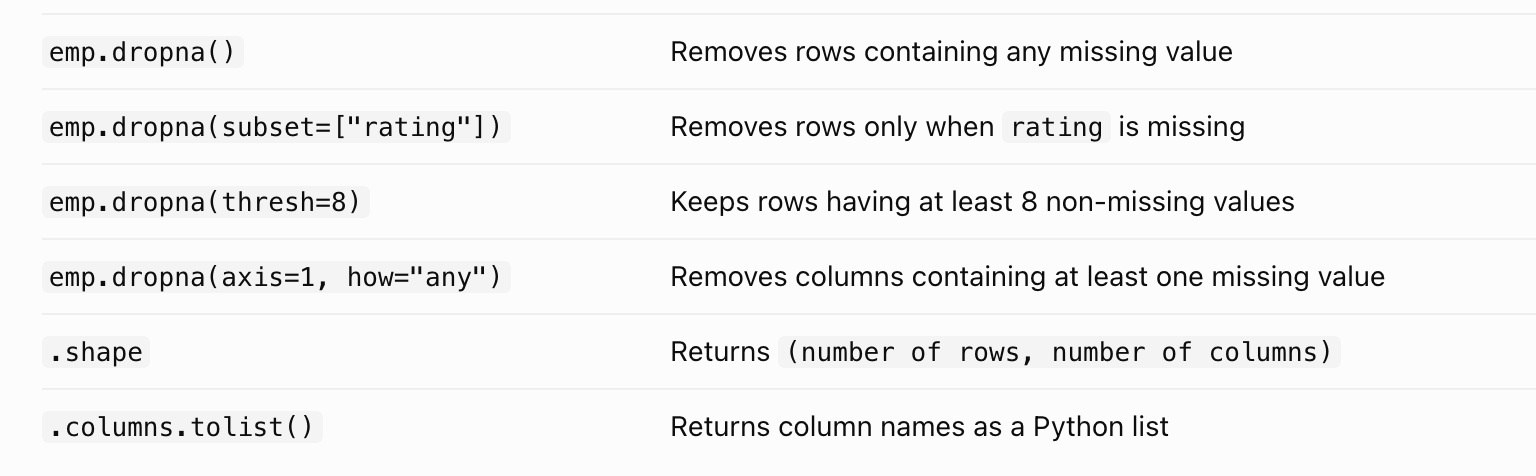

In [ ]:
print(emp.dropna().shape)                          # any NaN -> Removes rows containing any missing value
print(emp.dropna(subset=["rating"]).shape)            # only look at 'rating'
print(emp.dropna(thresh=8).shape)                     # keep rows with >= 8 non-NaN
print(emp.dropna(axis=1, how="any").columns.tolist()) # drop columns with NaN

(173, 9)


(188, 9)
(204, 9)
['emp_id', 'name', 'department', 'age', 'salary', 'join_date']


## Filling
Strategies: constant, statistic (mean/median/mode), forward/back fill, group-wise statistic, interpolation.

In [259]:
emp.head(5)

,emp_id,name,department,city,age,salary,join_date,rating,email
0,1001,Priya Iyer,Finance,Mumbai,52,102500.0,2015-07-30,2.0,priya.iyer@company.com
1,1002,Kavya Patel,Marketing,Delhi,49,69400.0,2016-08-28,3.0,kavya.patel@company.com
2,1003,Rohan Mehta,Sales,Bengaluru,43,83000.0,2022-08-12,3.0,rohan.mehta@company.com
3,1004,Priya Nair,Engineering,Hyderabad,55,30000.0,2019-11-11,4.0,priya.nair@company.com
4,1005,Vikram Sharma,Engineering,NaN,26,49600.0,2016-02-29,5.0,vikram.sharma@company.com


In [267]:
dg4 = emp.copy()
dg4["city"] = dg4["city"].fillna("Unknown")                       # constant
dg4["rating"] = dg4["rating"].fillna(dg4["rating"].median())   # statistic
dg4["email"] = dg4["email"].fillna("not_provided@company.com")
print(dg4.isna().sum())


print(dg4["emp_id"].mean())
print(dg4["age"].median())

emp_id        0
name          0
department    0
city          0
age           0
salary        0
join_date     0
rating        0
email         0
dtype: int64
1100.1121951219511
41.0


In [45]:
# group-wise fill: use the median rating of each department
emp["rating_filled"] = emp["rating"].fillna(emp.groupby("department")["rating"].transform("median"))
print(emp[["department", "rating", "rating_filled"]][emp["rating"].isna()].head())

     department  rating  rating_filled
5   Engineering     NaN            3.0
21        Sales     NaN            4.0
29  Engineering     NaN            3.0
36        Sales     NaN            4.0
54  Engineering     NaN            3.0


In [46]:
# forward / backward fill and interpolation (time-series friendly)
ts = pd.Series([1.0, np.nan, np.nan, 4.0, np.nan, 6.0])
print(pd.DataFrame({"orig": ts, "ffill": ts.ffill(), "bfill": ts.bfill(),
                    "linear": ts.interpolate()}))

   orig  ffill  bfill  linear
0   1.0    1.0    1.0     1.0
1   NaN    1.0    4.0     2.0
2   NaN    1.0    4.0     3.0
3   4.0    4.0    4.0     4.0
4   NaN    4.0    6.0     5.0
5   6.0    6.0    6.0     6.0


## Replacing sentinel values
Sometimes missing data is encoded as `-1`, `"N/A"`, `"?"`. Convert these to real `NaN` first.

In [47]:
messy = pd.DataFrame({"a": [1, -999, 3], "b": ["x", "N/A", "z"]})
messy.replace({-999: np.nan, "N/A": np.nan})

,a,b
0,1.0,x
1,NaN,NaN
2,3.0,z


### Rules of thumb
- Understand *why* data is missing before deciding what to do.
- Dropping is safe only when few rows are affected.
- Never fill the target variable with the mean without thinking - it creates fake data.

---
# 09 Data Cleaning: Duplicates, Renaming, Replacing & Outliers

`Beginner`

> **Definition.** **Data cleaning** is the process of fixing or removing incorrect, duplicated, inconsistent or outlying data so the dataset is reliable for analysis.

In [268]:
emp = pd.read_csv("data/employees.csv", parse_dates=["join_date"])
print("rows before:", len(emp))
emp

rows before: 205


,emp_id,name,department,city,age,salary,join_date,rating,email
0,1001,Priya Iyer,Finance,Mumbai,52,102500.0,2015-07-30,2.0,priya.iyer@company.com
1,1002,Kavya Patel,Marketing,Delhi,49,69400.0,2016-08-28,3.0,kavya.patel@company.com
2,1003,Rohan Mehta,Sales,Bengaluru,43,83000.0,2022-08-12,3.0,rohan.mehta@company.com
3,1004,Priya Nair,Engineering,Hyderabad,55,30000.0,2019-11-11,4.0,priya.nair@company.com
4,1005,Vikram Sharma,Engineering,NaN,26,49600.0,2016-02-29,5.0,vikram.sharma@company.com
...,...,...,...,...,...,...,...,...,...
200,1059,Aarav Verma,Engineering,Pune,38,68700.0,2017-07-25,3.0,aarav.verma@company.com
201,1041,Nikhil Patel,Finance,Delhi,48,80300.0,2016-06-30,5.0,nikhil.patel@company.com
202,1035,Priya Patel,Marketing,Hyderabad,24,80200.0,2024-05-11,4.0,NaN
203,1103,Pooja Gupta,Sales,NaN,56,71300.0,2021-03-10,3.0,pooja.gupta@company.com


In [273]:
# 1. dict of lists (keys = column names)
duplicate = pd.DataFrame({
    "name": ["Naresh", "Kumar", "Devi", "adi"],
    "age": [25, 30, 35, 28],
    "city": ["Bangalore", "Madanapalle", "Chennai", "Hyderabad"],
    "city1": ["Bangalore", "Madanapalle", "Chennai", "Hyderabad"]
})
duplicate

,name,age,city,city1
0,Naresh,25,Bangalore,Bangalore
1,Kumar,30,Madanapalle,Madanapalle
2,Devi,35,Chennai,Chennai
3,adi,28,Hyderabad,Hyderabad


In [275]:
duplicate.duplicated()

0    False
1    False
2    False
3    False
dtype: bool

In [282]:
duplicate.drop_duplicates(subset=["city","city1"])

,name,age,city,city1
0,Naresh,25,Bangalore,Bangalore
1,Kumar,30,Madanapalle,Madanapalle
2,Devi,35,Chennai,Chennai
3,adi,28,Hyderabad,Hyderabad


In [284]:
duplicate.duplicated()

0    False
1    False
2    False
3    False
dtype: bool

## Duplicates

In [308]:
dpl=pd.read_csv("data/sales.csv")

print(dpl.duplicated().sum())                 # fully duplicated rows
dpl.duplicated()
dpl = dpl.drop_duplicates()                         # keep first occurrence
emp = dpl.drop_duplicates(subset=["customer_id"], keep="last")   # based on key columns
print("rows after:", len(emp))

6
rows after: 50


## Renaming and reordering

In [ ]:
emp = emp.rename(columns={"emp_id": "employee_id", "join_date": "joined_on"})
emp.columns = emp.columns.str.lower().str.replace(" ", "_")   # normalise all names
emp = emp[["employee_id", "name", "department", "city", "age", "salary", "rating", "joined_on", "email"]]
emp.columns.tolist()

## Cleaning text
Extra whitespace and inconsistent case are the most common problems in text columns.

In [ ]:
print(emp["name"].head(3).tolist())
emp["name"] = emp["name"].str.strip().str.title()
print(emp["name"].head(3).tolist())

## Replacing values

In [52]:
emp["department"] = emp["department"].replace({"HR": "Human Resources"})
emp["city"] = emp["city"].replace("Bengaluru", "Bangalore")
emp["department"].value_counts()

department
Engineering        68
Sales              53
Finance            31
Marketing          28
Human Resources    20
Name: count, dtype: int64

## Outliers
**IQR rule**: a value is an outlier if it lies below `Q1 - 1.5*IQR` or above `Q3 + 1.5*IQR`.

In [ ]:
q1, q3 = emp["salary"].quantile([.25, .75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = emp[(emp["salary"] < low) | (emp["salary"] > high)]
print(f"bounds: {low:,.0f} - {high:,.0f}   outliers: {len(outliers)}")

emp["salary_capped"] = emp["salary"].clip(lower=low, upper=high)   # winsorise

## Validation helpers

In [54]:
assert emp["employee_id"].is_unique, "duplicate IDs!"
assert emp["age"].between(18, 70).all()
print("all checks passed")

all checks passed


In [55]:
emp = emp.reset_index(drop=True)    # tidy the index after dropping rows
emp.head(3)

,employee_id,name,department,city,age,salary,rating,joined_on,email,salary_capped
0,1001,Priya Iyer,Finance,Mumbai,52,102500.0,2.0,2015-07-30,priya.iyer@company.com,102500.0
1,1002,Kavya Patel,Marketing,Delhi,49,69400.0,3.0,2016-08-28,kavya.patel@company.com,69400.0
2,1003,Rohan Mehta,Sales,Bangalore,43,83000.0,3.0,2022-08-12,rohan.mehta@company.com,83000.0


---
# 10 Column Operations: assign, apply, map, where, cut

`Intermediate`

> **Definition.** Creating new columns from existing ones is the heart of feature engineering. Prefer **vectorised** operations; use `apply`/`map` only when no vectorised alternative exists.

In [56]:
sales = pd.read_csv("data/sales.csv", parse_dates=["order_date"])
emp = pd.read_csv("data/employees.csv", parse_dates=["join_date"]).drop_duplicates()

## Vectorised arithmetic and `assign`
`assign` creates new columns and returns a new DataFrame - perfect for method chaining.

In [57]:
sales = sales.assign(
    discount=sales["discount"].fillna(0),
    gross=lambda d: d["quantity"] * d["unit_price"],
    revenue=lambda d: d["gross"] * (1 - d["discount"]),
)
sales[["quantity", "unit_price", "discount", "gross", "revenue"]].head()

,quantity,unit_price,discount,gross,revenue
0,4,32942.65,0.0,131770.60,131770.60
1,1,5855.12,0.1,5855.12,5269.61
2,1,1671.22,0.0,1671.22,1671.22
3,7,29.59,0.0,207.13,207.13
4,4,3152.62,0.0,12610.48,12610.48


## `map` - element-wise on a Series (dict, function or Series)

In [58]:
tier = {"Electronics": "High", "Furniture": "Medium", "Stationery": "Low", "Accessories": "Low"}
sales["value_tier"] = sales["category"].map(tier)
sales["value_tier"].value_counts()

value_tier
High      375
Low       371
Medium    254
Name: count, dtype: int64

## `apply` - run a function on each element, row or column

In [59]:
# column-wise apply on a Series
emp["salary_k"] = emp["salary"].apply(lambda x: round(x / 1000, 1))

# row-wise apply (axis=1) - slow, use only when needed
def label(row):
    return f"{row['name'].strip()} ({row['department']}, {row['city']})"

emp.apply(label, axis=1).head(3)

0      Priya Iyer (Finance, Mumbai)
1    Kavya Patel (Marketing, Delhi)
2    Rohan Mehta (Sales, Bengaluru)
dtype: str

In [60]:
# DataFrame.map applies a function to every cell (replaces applymap in pandas >= 2.1)
nums = pd.DataFrame({"a": [1.234, 2.345], "b": [3.456, 4.567]})
nums.map(lambda v: f"{v:.1f}")

,a,b
0,1.2,3.5
1,2.3,4.6


## Conditional columns: `np.where`, `np.select`, `where`, `mask`

In [61]:
emp["is_senior"] = np.where(emp["age"] >= 45, "Senior", "Regular")

conditions = [emp["salary"] < 50000, emp["salary"].between(50000, 90000), emp["salary"] > 90000]
labels = ["Low", "Mid", "High"]
emp["salary_band"] = np.select(conditions, labels, default="Unknown")
emp["salary_band"].value_counts()

salary_band
Mid     123
High     49
Low      31
Name: count, dtype: int64

In [62]:
# where keeps values where condition is True, otherwise replaces
print(emp["salary"].where(emp["salary"] < 100000, 100000).max())

100000.0


## Binning: `cut` (fixed edges) and `qcut` (equal-sized quantiles)

In [63]:
emp["age_group"] = pd.cut(emp["age"], bins=[17, 30, 40, 50, 100],
                          labels=["<=30", "31-40", "41-50", "50+"])
emp["salary_quartile"] = pd.qcut(emp["salary"], q=4, labels=["Q1", "Q2", "Q3", "Q4"])
print(emp["age_group"].value_counts().sort_index())
print(emp["salary_quartile"].value_counts().sort_index())

age_group
<=30     42
31-40    56
41-50    57
50+      48
Name: count, dtype: int64
salary_quartile
Q1    51
Q2    52
Q3    49
Q4    51
Name: count, dtype: int64


## Speed comparison: vectorised vs `apply`

In [64]:
import time

t = time.perf_counter(); r1 = sales["quantity"] * sales["unit_price"]; t1 = time.perf_counter() - t
t = time.perf_counter(); r2 = sales.apply(lambda r: r["quantity"] * r["unit_price"], axis=1); t2 = time.perf_counter() - t
print(f"vectorised: {t1*1000:.2f} ms | apply(axis=1): {t2*1000:.2f} ms | {t2/t1:.0f}x slower")

vectorised: 0.31 ms | apply(axis=1): 7.34 ms | 24x slower

---
# 11 Working with Text Data (.str accessor)

`Intermediate`

> **Definition.** The **`.str` accessor** exposes vectorised string methods (lower, split, contains, extract, replace...) that work on whole columns and safely skip missing values.

In [65]:
emp = pd.read_csv("data/employees.csv").drop_duplicates()
names = emp["name"].str.strip()
names.head()

0       Priya Iyer
1      Kavya Patel
2      Rohan Mehta
3       Priya Nair
4    Vikram Sharma
Name: name, dtype: str

In [66]:
print(names.str.upper().head(2).tolist())
print(names.str.lower().head(2).tolist())
print(names.str.len().head(2).tolist())
print(names.str.startswith("A").sum())
print(names.str.contains("sh", case=False).sum())

['PRIYA IYER', 'KAVYA PATEL']
['priya iyer', 'kavya patel']
[10, 11]
42
47


## Split into multiple columns

In [67]:
parts = names.str.split(" ", expand=True)
parts.columns = ["first_name", "last_name"]
parts.head()

,first_name,last_name
0,Priya,Iyer
1,Kavya,Patel
2,Rohan,Mehta
3,Priya,Nair
4,Vikram,Sharma


In [68]:
emp[["first_name", "last_name"]] = parts
emp["last_name"].value_counts().head()

last_name
Patel    26
Verma    25
Iyer     24
Mehta    19
Nair     19
Name: count, dtype: int64

## Regex extraction and replacement

In [69]:
# extract the e-mail user and domain
emp[["user", "domain"]] = emp["email"].str.extract(r"(.+)@(.+)")
print(emp[["email", "user", "domain"]].head(3))

# regex replace
print(emp["email"].str.replace(r"\.", "_", regex=True).head(3).tolist())

                     email         user       domain
0   priya.iyer@company.com   priya.iyer  company.com
1  kavya.patel@company.com  kavya.patel  company.com
2  rohan.mehta@company.com  rohan.mehta  company.com
['priya_iyer@company_com', 'kavya_patel@company_com', 'rohan_mehta@company_com']


In [70]:
# join / concatenate / slice / pad
print((emp["first_name"] + " " + emp["last_name"].str.upper()).head(2).tolist())
print(emp["first_name"].str.cat(emp["last_name"], sep="_").head(2).tolist())
print(emp["first_name"].str[:3].head(3).tolist())
print(pd.Series(["7", "42"]).str.zfill(4).tolist())

['Priya IYER', 'Kavya PATEL']
['Priya_Iyer', 'Kavya_Patel']
['Pri', 'Kav', 'Roh']
['0007', '0042']


In [71]:
# count missing emails, and find non-company emails
print(emp["email"].isna().sum())
print((~emp["email"].str.endswith("@company.com", na=True)).sum())

9
0


---
# 12 Date & Time Series Basics

`Intermediate`

> **Definition.** Pandas has first-class support for dates and times: `Timestamp`, `Timedelta`, `DatetimeIndex`, the `.dt` accessor, `resample` for frequency conversion and time-zone handling.

In [72]:
sales = pd.read_csv("data/sales.csv", parse_dates=["order_date"])
sales["revenue"] = sales["quantity"] * sales["unit_price"] * (1 - sales["discount"].fillna(0))
print(sales["order_date"].dtype)

datetime64[us]


## The `.dt` accessor

In [73]:
d = sales["order_date"].dt
sales["year"], sales["month"], sales["day"] = d.year, d.month, d.day
sales["weekday"] = d.day_name()
sales["quarter"] = d.quarter
sales["is_weekend"] = d.dayofweek >= 5
sales["month_name"] = d.month_name()
sales[["order_date", "year", "month", "weekday", "quarter", "is_weekend"]].head()

,order_date,year,month,weekday,quarter,is_weekend
0,2024-01-01,2024,1,Monday,1,False
1,2024-01-02,2024,1,Tuesday,1,False
2,2024-01-03,2024,1,Wednesday,1,False
3,2024-01-03,2024,1,Wednesday,1,False
4,2024-01-03,2024,1,Wednesday,1,False


## Creating dates: `date_range`, `Timedelta`, `DateOffset`

In [74]:
print(pd.date_range("2024-01-01", periods=5, freq="D"))
print(pd.date_range("2024-01-31", periods=4, freq="ME"))     # month-end
print(pd.date_range("2024-01-01", "2024-03-01", freq="W-MON"))

ts = pd.Timestamp("2024-03-15")
print(ts + pd.Timedelta(days=10), ts + pd.DateOffset(months=1))

DatetimeIndex(['2024-01-01', '2024-01-02', '2024-01-03', '2024-01-04', '2024-01-05'], dtype='datetime64[us]', freq='D')
DatetimeIndex(['2024-01-31', '2024-02-29', '2024-03-31', '2024-04-30'], dtype='datetime64[us]', freq='ME')
DatetimeIndex(['2024-01-01', '2024-01-08', '2024-01-15', '2024-01-22', '2024-01-29', '2024-02-05', '2024-02-12',
               '2024-02-19', '2024-02-26'],
              dtype='datetime64[us]', freq='W-MON')
2024-03-25 00:00:00 2024-04-15 00:00:00


## Date arithmetic

In [75]:
emp = pd.read_csv("data/employees.csv", parse_dates=["join_date"])
today = pd.Timestamp("2025-01-01")
emp["tenure_days"] = (today - emp["join_date"]).dt.days
emp["tenure_years"] = (emp["tenure_days"] / 365.25).round(1)
emp[["name", "join_date", "tenure_years"]].head(3)

,name,join_date,tenure_years
0,Priya Iyer,2015-07-30,9.4
1,Kavya Patel,2016-08-28,8.3
2,Rohan Mehta,2022-08-12,2.4


## DatetimeIndex: slicing and `resample`
Set the date column as the index to slice by date strings and aggregate by period.

In [76]:
ts = sales.set_index("order_date").sort_index()
print(ts.loc["2024-03"].shape)                      # whole month
print(ts.loc["2024-01-15":"2024-01-20"].shape)      # date range

(84, 16)
(17, 16)


In [77]:
monthly = ts["revenue"].resample("ME").sum()      # 'ME' = month end
weekly = ts["revenue"].resample("W").agg(["sum", "count"])
print(monthly.head(3))
print(weekly.head(3))

order_date
2024-01-31    3.01e+06
2024-02-29    3.15e+06
2024-03-31    5.15e+06
Freq: ME, Name: revenue, dtype: float64
                  sum  count
order_date                  
2024-01-07  400787.79     17
2024-01-14  930032.38     23
2024-01-21  931915.53     21


## Time zones and periods

In [78]:
t = pd.Timestamp("2024-06-01 09:00", tz="Asia/Kolkata")
print(t.tz_convert("UTC"))
print(pd.Period("2024-03", freq="M") + 2)
print(sales["order_date"].dt.to_period("M").value_counts().sort_index().head(3))

2024-06-01 03:30:00+00:00
2024-05
order_date
2024-01    85
2024-02    79
2024-03    84
Freq: M, Name: count, dtype: int64


In [79]:
# parse custom formats
print(pd.to_datetime("25-12-2024", format="%d-%m-%Y"))
print(pd.to_datetime(["2024-01-01", "bad"], errors="coerce"))

2024-12-25 00:00:00
DatetimeIndex(['2024-01-01', 'NaT'], dtype='datetime64[us]', freq=None)


---
# 13 Sorting, Ranking & Top-N

`Intermediate`

> **Definition.** Sorting orders rows by values or index labels; ranking assigns an ordinal position to each value; `nlargest`/`nsmallest` quickly retrieve top-N rows.

In [80]:
emp = pd.read_csv("data/employees.csv").drop_duplicates(subset="emp_id")

In [81]:
# sort by one or multiple columns, mixed order
emp.sort_values("salary", ascending=False)[["name", "salary"]].head(3)

,name,salary
54,Pooja Iyer,131100.0
99,Karan Joshi,127400.0
65,Divya Reddy,120200.0


In [82]:
emp.sort_values(["department", "salary"], ascending=[True, False])[["department", "name", "salary"]].head(5)

,department,name,salary
54,Engineering,Pooja Iyer,131100.0
65,Engineering,Divya Reddy,120200.0
8,Engineering,Arjun Verma,118900.0
12,Engineering,Meera Nair,110400.0
53,Engineering,Meera Nair,110400.0


In [83]:
# NaN position and custom key
print(emp.sort_values("rating", na_position="first")["rating"].head(3).tolist())
emp.sort_values("name", key=lambda s: s.str.strip().str.lower()).head(3)["name"].tolist()

[nan, nan, nan]


['Aarav Gupta', 'Aarav Iyer', 'Aarav Iyer']

In [84]:
emp.sort_index(ascending=False).head(2)       # sort by index

,emp_id,name,department,city,age,salary,join_date,rating,email
199,1200,Anita Singh,Sales,Bengaluru,45,50900.0,2019-10-01,2.0,anita.singh@company.com
198,1199,Aarav Verma,Sales,Hyderabad,52,79500.0,2021-06-15,4.0,aarav.verma@company.com


## Top-N

In [85]:
print(emp.nlargest(3, "salary")[["name", "salary"]])
print(emp.nsmallest(3, "age")[["name", "age"]])

           name    salary
54   Pooja Iyer  131100.0
99  Karan Joshi  127400.0
65  Divya Reddy  120200.0
            name  age
37   Kavya Patel   22
69   Karan Patel   22
120  Rahul Reddy   22


## Ranking
`method` controls how ties are broken: `average` (default), `min`, `max`, `first`, `dense`.

In [86]:
emp["salary_rank"] = emp["salary"].rank(ascending=False, method="min")
emp["dept_rank"] = emp.groupby("department")["salary"].rank(ascending=False, method="dense")
emp[["name", "department", "salary", "salary_rank", "dept_rank"]].sort_values("salary_rank").head(5)

,name,department,salary,salary_rank,dept_rank
54,Pooja Iyer,Engineering,131100.0,1.0,1.0
99,Karan Joshi,HR,127400.0,2.0,1.0
65,Divya Reddy,Engineering,120200.0,3.0,2.0
176,Anita Patel,Marketing,120100.0,4.0,1.0
8,Arjun Verma,Engineering,118900.0,5.0,3.0


In [87]:
# row label of the max / min value
print(emp.loc[emp["salary"].idxmax(), "name"])
print(emp["age"].idxmin())

# top earner in every department
emp.loc[emp.groupby("department")["salary"].idxmax(), ["department", "name", "salary"]]

Pooja Iyer
37


,department,name,salary
54,Engineering,Pooja Iyer,131100.0
15,Finance,Pooja Gupta,115100.0
99,HR,Karan Joshi,127400.0
176,Marketing,Anita Patel,120100.0
73,Sales,Aarav Gupta,115700.0


---
# 14 GroupBy & Aggregation (Split-Apply-Combine)

`Intermediate`

> **Definition.** `groupby` splits data into groups, applies a function (aggregate, transform, filter) to each group, and combines the results. It is the pandas equivalent of SQL `GROUP BY`.

In [88]:
sales = pd.read_csv("data/sales.csv", parse_dates=["order_date"])
sales["revenue"] = sales["quantity"] * sales["unit_price"] * (1 - sales["discount"].fillna(0))
emp = pd.read_csv("data/employees.csv").drop_duplicates()

## Basic aggregation

In [89]:
print(sales.groupby("region")["revenue"].sum().round(0))
print(sales.groupby("category")["quantity"].mean().round(2))
print(sales.groupby(["region", "category"])["revenue"].sum().round(0).head(6))

region
East     1.37e+07
North    1.48e+07
South    1.23e+07
West     1.15e+07
Name: revenue, dtype: float64
category
Accessories    3.81
Electronics    3.97
Furniture      3.86
Stationery     4.00
Name: quantity, dtype: float64
region  category   
East    Accessories    2.49e+05
        Electronics    1.07e+07
        Furniture      2.73e+06
        Stationery     1.40e+04
North   Accessories    2.24e+05
        Electronics    1.25e+07
Name: revenue, dtype: float64


## `agg` with several functions and **named aggregation** (recommended)

In [90]:
summary = sales.groupby("category").agg(
    orders=("order_id", "count"),
    total_qty=("quantity", "sum"),
    avg_price=("unit_price", "mean"),
    revenue=("revenue", "sum"),
    max_order=("revenue", "max"),
).round(1)
summary.sort_values("revenue", ascending=False)

,orders,total_qty,avg_price,revenue,max_order
category,,,,,
Electronics,375,1490,29574.1,4.27e+07,409618.9
Furniture,254,980,9236.9,8.61e+06,89256.8
Accessories,132,503,1792.4,8.67e+05,13855.6
Stationery,239,957,70.2,6.59e+04,915.5


In [91]:
emp.groupby("department")["salary"].agg(["count", "mean", "median", "min", "max"]).round(0)

,count,mean,median,min,max
department,,,,,
Engineering,68,71334.0,68450.0,30000.0,131100.0
Finance,31,73906.0,80500.0,30000.0,115100.0
HR,20,76315.0,73450.0,36000.0,127400.0
Marketing,29,73538.0,80200.0,30000.0,120100.0
Sales,55,76467.0,78500.0,30000.0,115700.0


## `transform` - result has the same shape as the input
Useful for group-wise normalisation and filling.

In [92]:
sales["region_share_%"] = (sales["revenue"] / sales.groupby("region")["revenue"].transform("sum") * 100).round(3)
emp["salary_vs_dept_avg"] = emp["salary"] - emp.groupby("department")["salary"].transform("mean")
emp[["department", "salary", "salary_vs_dept_avg"]].head()

,department,salary,salary_vs_dept_avg
0,Finance,102500.0,28593.55
1,Marketing,69400.0,-4137.93
2,Sales,83000.0,6532.73
3,Engineering,30000.0,-41333.82
4,Engineering,49600.0,-21733.82


## `filter` - keep or drop entire groups

In [93]:
big_depts = emp.groupby("department").filter(lambda g: len(g) > 25)
print(big_depts["department"].unique())

<ArrowStringArray>
['Finance', 'Marketing', 'Sales', 'Engineering']
Length: 4, dtype: str

## `apply` - arbitrary per-group logic

In [94]:
# top-2 earners per department
emp.groupby("department", group_keys=False)[["name", "salary"]].apply(lambda g: g.nlargest(2, "salary")).head(6)

,name,salary
54,Pooja Iyer,131100.0
65,Divya Reddy,120200.0
15,Pooja Gupta,115100.0
196,Neha Reddy,104700.0
99,Karan Joshi,127400.0
193,Priya Mehta,113000.0


## Time-based grouping, `size` vs `count`, group numbering

In [95]:
print(sales.groupby(pd.Grouper(key="order_date", freq="QE"))["revenue"].sum().round(0))

# size counts rows (incl. NaN); count counts non-null values
print(emp.groupby("department").size())
print(emp.groupby("department")["rating"].count())

emp["cum_in_dept"] = emp.groupby("department").cumcount() + 1   # 1,2,3.. inside each group

order_date
2024-03-31    1.13e+07
2024-06-30    1.47e+07
2024-09-30    1.37e+07
2024-12-31    1.26e+07
Freq: QE-DEC, Name: revenue, dtype: float64
department
Engineering    68
Finance        31
HR             20
Marketing      29
Sales          55
dtype: int64
department
Engineering    62
Finance        30
HR             20
Marketing      27
Sales          47
Name: rating, dtype: int64


In [96]:
# iterate over groups
for name, grp in list(sales.groupby("region"))[:2]:
    print(name, grp.shape)

# as_index=False keeps keys as columns
sales.groupby("region", as_index=False)["revenue"].sum().round(0)

East (258, 11)
North (277, 11)


,region,revenue
0,East,1.37e+07
1,North,1.48e+07
2,South,1.23e+07
3,West,1.15e+07


---
# 15 Combining Data: concat, merge, join

`Intermediate`

> **Definition.** Pandas can stack tables (`concat`), join them on keys like SQL (`merge`/`join`), and align on indexes. Choosing the right join type is critical for correct results.

In [97]:
sales = pd.read_csv("data/sales.csv", parse_dates=["order_date"])
customers = pd.read_csv("data/customers.csv", parse_dates=["signup_date"])

## `concat` - stack vertically (axis=0) or side-by-side (axis=1)

In [98]:
jan = sales[sales["order_date"].dt.month == 1]
feb = sales[sales["order_date"].dt.month == 2]

stacked = pd.concat([jan, feb], ignore_index=True)
print(len(jan), len(feb), len(stacked))

# keys build a hierarchical index to remember the source
pd.concat({"jan": jan.head(2), "feb": feb.head(2)})[["order_id", "product"]]

85 79 164


order_id   product
jan 0       5303     Phone
    1       5740     Chair
feb 85      5172  Backpack
    86      5249  Backpack

In [99]:
left = pd.DataFrame({"a": [1, 2]}, index=["x", "y"])
right = pd.DataFrame({"b": [3, 4]}, index=["y", "z"])
print(pd.concat([left, right], axis=1))               # outer join on index
print(pd.concat([left, right], axis=1, join="inner"))

     a    b
x  1.0  NaN
y  2.0  3.0
z  NaN  4.0
   a  b
y  2  3


## `merge` - SQL-style joins

| `how` | Keeps |
|-------|-------|
| `inner` (default) | only keys present in both |
| `left` | all left rows |
| `right` | all right rows |
| `outer` | all rows from both |
| `cross` | cartesian product |

In [100]:
merged = sales.merge(customers, on="customer_id", how="left")
merged[["order_id", "customer_id", "customer_name", "segment", "region"]].head()

,order_id,customer_id,customer_name,segment,region
0,5303,44,Customer_44,Consumer,East
1,5740,28,Customer_28,Consumer,West
2,5990,33,Customer_33,Small Business,East
3,5684,3,Customer_03,Corporate,West
4,5028,4,Customer_04,Consumer,West


In [101]:
# small demo showing the four join types
a = pd.DataFrame({"key": [1, 2, 3], "left_val": ["a", "b", "c"]})
b = pd.DataFrame({"key": [2, 3, 4], "right_val": ["x", "y", "z"]})
for how in ["inner", "left", "right", "outer"]:
    print(f"--- {how} ---")
    print(a.merge(b, on="key", how=how))

--- inner ---
   key left_val right_val
0    2        b         x
1    3        c         y
--- left ---
   key left_val right_val
0    1        a       NaN
1    2        b         x
2    3        c         y
--- right ---
   key left_val right_val
0    2        b         x
1    3        c         y
2    4      NaN         z
--- outer ---
   key left_val right_val
0    1        a       NaN
1    2        b         x
2    3        c         y
3    4      NaN         z


In [102]:
# different key names, overlapping column names, diagnostics and validation
orders = sales.head(5).rename(columns={"customer_id": "cust"})
res = orders.merge(customers, left_on="cust", right_on="customer_id",
                   how="left", suffixes=("_order", "_cust"), indicator=True, validate="m:1")
print(res["_merge"].value_counts())

_merge
both          5
left_only     0
right_only    0
Name: count, dtype: int64


## `join` - index-based shortcut

In [103]:
cust_idx = customers.set_index("customer_id")
sales.head(3).join(cust_idx, on="customer_id")[["order_id", "customer_name", "segment"]]

,order_id,customer_name,segment
0,5303,Customer_44,Consumer
1,5740,Customer_28,Consumer
2,5990,Customer_33,Small Business


## Advanced: `merge_asof`, `combine_first`

In [104]:
# merge_asof: match each trade with the latest quote before it
quotes = pd.DataFrame({"time": pd.to_datetime(["10:00", "10:05", "10:10"], format="%H:%M"), "price": [100, 101, 102]})
trades = pd.DataFrame({"time": pd.to_datetime(["10:03", "10:07"], format="%H:%M"), "qty": [5, 8]})
print(pd.merge_asof(trades, quotes, on="time"))

# combine_first: fill gaps in one frame from another
x = pd.DataFrame({"v": [1, np.nan, 3]})
y = pd.DataFrame({"v": [10, 20, 30]})
print(x.combine_first(y))

                 time  qty  price
0 1900-01-01 10:03:00    5    100
1 1900-01-01 10:07:00    8    101
      v
0   1.0
1  20.0
2   3.0


In [105]:
# find customers who never ordered (anti-join)
never = customers.merge(sales[["customer_id"]].drop_duplicates(), on="customer_id", how="left", indicator=True)
print(never[never["_merge"] == "left_only"].shape[0], "customers without orders")

0 customers without orders


---
# 16 Reshaping: pivot, melt, stack, crosstab, dummies

`Intermediate`

> **Definition.** Reshaping converts data between **long** (one observation per row) and **wide** (one column per category) formats, and builds summary tables such as spreadsheet pivot tables.

In [106]:
sales = pd.read_csv("data/sales.csv", parse_dates=["order_date"])
sales["revenue"] = sales["quantity"] * sales["unit_price"] * (1 - sales["discount"].fillna(0))
sales["month"] = sales["order_date"].dt.month

## `pivot_table` - aggregate + reshape (like Excel)

In [107]:
pt = sales.pivot_table(
    index="region", columns="category", values="revenue",
    aggfunc="sum", fill_value=0, margins=True, margins_name="Total",
).round(0)
pt

category,Accessories,Electronics,Furniture,Stationery,Total
region,,,,,
East,248862.0,1.07e+07,2.73e+06,14049.0,1.37e+07
North,224305.0,1.25e+07,2.09e+06,18463.0,1.48e+07
South,204915.0,1.04e+07,1.67e+06,16832.0,1.23e+07
West,188999.0,9.13e+06,2.13e+06,16568.0,1.15e+07
Total,867082.0,4.27e+07,8.61e+06,65912.0,5.22e+07


In [108]:
# several values/aggregations
sales.pivot_table(index="category", values=["revenue", "quantity"],
                  aggfunc={"revenue": "sum", "quantity": ["mean", "max"]}).round(1)

quantity        revenue
                 max mean       sum
category                           
Accessories        7  3.8  8.67e+05
Electronics        7  4.0  4.27e+07
Furniture          7  3.9  8.61e+06
Stationery         7  4.0  6.59e+04

## `pivot` - reshape without aggregation (index/column pairs must be unique)

In [109]:
tidy = sales.groupby(["month", "region"], as_index=False)["revenue"].sum()
wide = tidy.pivot(index="month", columns="region", values="revenue").round(0)
wide.head(4)

region,East,North,South,West
month,,,,
1,6.89e+05,9.28e+05,7.58e+05,6.32e+05
2,6.66e+05,4.58e+05,8.41e+05,1.19e+06
3,1.39e+06,1.81e+06,1.19e+06,7.57e+05
4,1.66e+06,1.65e+06,1.14e+06,7.69e+05


## `melt` - wide to long

In [110]:
long = wide.reset_index().melt(id_vars="month", var_name="region", value_name="revenue")
long.head()

,month,region,revenue
0,1,East,6.89e+05
1,2,East,6.66e+05
2,3,East,1.39e+06
3,4,East,1.66e+06
4,5,East,7.66e+05


## `stack` / `unstack` - move column levels to/from the row index

In [111]:
stacked = wide.stack()          # Series with (month, region) MultiIndex
print(stacked.head(3))
print(stacked.unstack().head(2))

month  region
1      East      688987.0
       North     928213.0
       South     758191.0
dtype: float64
region      East     North     South      West
month                                         
1       688987.0  928213.0  758191.0  6.32e+05
2       666498.0  458498.0  841337.0  1.19e+06


## `crosstab` - frequency tables

In [112]:
print(pd.crosstab(sales["region"], sales["category"]))
print(pd.crosstab(sales["region"], sales["category"], normalize="index").round(2))

category  Accessories  Electronics  Furniture  Stationery
region                                                   
East               35           95         73          55
North              38          112         57          70
South              30           84         61          61
West               29           84         63          53


category  Accessories  Electronics  Furniture  Stationery
region                                                   
East             0.14         0.37       0.28        0.21
North            0.14         0.40       0.21        0.25
South            0.13         0.36       0.26        0.26
West             0.13         0.37       0.28        0.23


## `get_dummies` - one-hot encoding

In [113]:
pd.get_dummies(sales[["region"]].head(5), dtype=int)
# pd.get_dummies(df, columns=["region"], drop_first=True)

,region_East,region_West
0,1,0
1,0,1
2,1,0
3,0,1
4,0,1


## `explode` - one row per list element

In [114]:
df = pd.DataFrame({"user": ["a", "b"], "tags": [["x", "y"], ["z"]]})
df.explode("tags")

,user,tags
0,a,x
0,a,y
1,b,z


---
# 17 MultiIndex (Hierarchical Indexing)

`Advanced`

> **Definition.** A **MultiIndex** gives rows (or columns) multiple index levels, letting you work with higher-dimensional data in a 2-D table.

In [115]:
sales = pd.read_csv("data/sales.csv", parse_dates=["order_date"])
sales["revenue"] = sales["quantity"] * sales["unit_price"] * (1 - sales["discount"].fillna(0))

mi = sales.groupby(["region", "category"])["revenue"].sum().round(0)
print(mi.head(6))
print(mi.index.names, mi.index.nlevels)

region  category   
East    Accessories    2.49e+05
        Electronics    1.07e+07
        Furniture      2.73e+06
        Stationery     1.40e+04
North   Accessories    2.24e+05
        Electronics    1.25e+07
Name: revenue, dtype: float64
['region', 'category'] 2


## Selecting with a MultiIndex

In [116]:
print(mi.loc["North"])                       # outer level
print(mi.loc[("North", "Electronics")])         # full key
print(mi.xs("Furniture", level="category"))     # cross-section on an inner level

category
Accessories    2.24e+05
Electronics    1.25e+07
Furniture      2.09e+06
Stationery     1.85e+04
Name: revenue, dtype: float64
12450188.0
region
East     2.73e+06
North    2.09e+06
South    1.67e+06
West     2.13e+06
Name: revenue, dtype: float64


In [117]:
df = mi.to_frame("revenue")
print(df.loc[(slice(None), ["Furniture", "Stationery"]), :].head(4))   # slicers (needs sorted index)

                    revenue
region category            
East   Furniture   2.73e+06
       Stationery  1.40e+04
North  Furniture   2.09e+06
       Stationery  1.85e+04


## Manipulating levels

In [118]:
print(mi.unstack("category").head(2))        # inner level -> columns
print(mi.swaplevel().sort_index().head(3))     # swap and sort
print(mi.reset_index().head(3))                # back to flat columns

category  Accessories  Electronics  Furniture  Stationery
region                                                   
East         248862.0     1.07e+07   2.73e+06     14049.0
North        224305.0     1.25e+07   2.09e+06     18463.0
category     region
Accessories  East      248862.0
             North     224305.0
             South     204915.0
Name: revenue, dtype: float64
  region     category   revenue
0   East  Accessories  2.49e+05
1   East  Electronics  1.07e+07
2   East    Furniture  2.73e+06


In [119]:
# build one directly
idx = pd.MultiIndex.from_product([["2023", "2024"], ["Q1", "Q2"]], names=["year", "quarter"])
pd.DataFrame({"sales": [10, 12, 14, 18]}, index=idx)

sales
year quarter       
2023 Q1          10
     Q2          12
2024 Q1          14
     Q2          18

In [120]:
# aggregate by a level without groupby
print(mi.groupby(level="region").sum())
print(mi.groupby(level=0).sum().sum())

region
East     1.37e+07
North    1.48e+07
South    1.23e+07
West     1.15e+07
Name: revenue, dtype: float64
52232418.0


---
# 18 Window Functions: rolling, expanding, ewm, shift

`Advanced`

> **Definition.** Window functions compute statistics over a sliding or growing subset of rows - essential for moving averages, running totals, growth rates and time-series features.

In [121]:
sales = pd.read_csv("data/sales.csv", parse_dates=["order_date"])
sales["revenue"] = sales["quantity"] * sales["unit_price"] * (1 - sales["discount"].fillna(0))
daily = sales.groupby("order_date")["revenue"].sum().asfreq("D", fill_value=0)
daily.head()

order_date
2024-01-01    131770.60
2024-01-02      5269.61
2024-01-03     14488.83
2024-01-04      9455.65
2024-01-05     26434.38
Freq: D, Name: revenue, dtype: float64

## `rolling` - fixed-size sliding window

In [122]:
r = pd.DataFrame({
    "daily": daily,
    "ma7": daily.rolling(7).mean(),                    # 7-day moving average
    "ma7_min3": daily.rolling(7, min_periods=3).mean(),
    "sum30": daily.rolling("30D").sum(),               # time-based window
})
r.iloc[5:10].round(0)

,daily,ma7,ma7_min3,sum30
order_date,,,,
2024-01-06,44896.0,NaN,38719.0,2.32e+05
2024-01-07,168472.0,57255.0,57255.0,4.01e+05
2024-01-08,376778.0,92256.0,92256.0,7.78e+05
2024-01-09,238247.0,125539.0,125539.0,1.02e+06
2024-01-10,53227.0,131073.0,131073.0,1.07e+06


## `expanding` and cumulative functions

In [123]:
out = pd.DataFrame({
    "daily": daily,
    "running_total": daily.cumsum(),
    "running_max": daily.cummax(),
    "expanding_mean": daily.expanding().mean(),
})
out.head(4).round(0)

,daily,running_total,running_max,expanding_mean
order_date,,,,
2024-01-01,131771.0,131771.0,131771.0,131771.0
2024-01-02,5270.0,137040.0,131771.0,68520.0
2024-01-03,14489.0,151529.0,131771.0,50510.0
2024-01-04,9456.0,160985.0,131771.0,40246.0


## `ewm` - exponentially weighted (recent values weigh more)

In [124]:
print(daily.ewm(span=7, adjust=False).mean().head(4).round(0))

order_date
2024-01-01    131771.0
2024-01-02    100145.0
2024-01-03     78731.0
2024-01-04     61412.0
Freq: D, Name: revenue, dtype: float64


## `shift`, `diff`, `pct_change` - lags and growth

In [125]:
monthly = daily.resample("ME").sum()
growth = pd.DataFrame({
    "revenue": monthly,
    "prev_month": monthly.shift(1),
    "change": monthly.diff(),
    "mom_growth_%": (monthly.pct_change() * 100).round(1),
})
growth.head(4).round(0)

,revenue,prev_month,change,mom_growth_%
order_date,,,,
2024-01-31,3.01e+06,NaN,NaN,NaN
2024-02-29,3.15e+06,3.01e+06,1.46e+05,5.0
2024-03-31,5.15e+06,3.15e+06,2.00e+06,63.0
2024-04-30,5.22e+06,5.15e+06,7.34e+04,1.0


In [126]:
# group-wise windows: running revenue per region
sales = sales.sort_values("order_date")
sales["region_running_total"] = sales.groupby("region")["revenue"].cumsum()

# rolling rank / custom function
daily.rolling(7).apply(lambda w: w.max() - w.min(), raw=True).dropna().head(3)

order_date
2024-01-07    163202.65
2024-01-08    371508.48
2024-01-09    367322.44
Freq: D, Name: revenue, dtype: float64

---
# 19 Categorical Data

`Advanced`

> **Definition.** The **category** dtype stores repeated strings as integer codes plus a lookup table. It saves memory, speeds up grouping and supports *ordered* categories (e.g. Low < Medium < High).

In [127]:
emp = pd.read_csv("data/employees.csv").drop_duplicates()

dept_obj = emp["department"]
dept_cat = emp["department"].astype("category")
print(dept_obj.memory_usage(deep=True), "->", dept_cat.memory_usage(deep=True), "bytes")
print(dept_cat.cat.categories)
print(dept_cat.cat.codes.head())

4815 -> 1902 bytes
Index(['Engineering', 'Finance', 'HR', 'Marketing', 'Sales'], dtype='str')
0    1
1    3
2    4
3    0
4    0
dtype: int8


## Ordered categoricals - enable correct sorting and comparison

In [128]:
size = pd.Series(["M", "S", "L", "M", "XL"], dtype=pd.CategoricalDtype(["S", "M", "L", "XL"], ordered=True))
print(size.sort_values().tolist())
print((size >= "L").tolist())
print(size.max())

['S', 'M', 'M', 'L', 'XL']
[False, False, True, False, True]
XL


## Managing categories

In [129]:
c = pd.Series(["a", "b", "a", "c"], dtype="category")
c = c.cat.add_categories(["d"]).cat.rename_categories({"a": "A"})
print(c.cat.categories.tolist())
print(c.value_counts())           # unused categories appear with 0
print(c.cat.remove_unused_categories().cat.categories.tolist())

['A', 'b', 'c', 'd']
A    2
b    1
c    1
d    0
Name: count, dtype: int64
['A', 'b', 'c']


In [130]:
# groupby on categoricals: observed=True hides empty groups
emp["rating_level"] = pd.cut(emp["rating"], [0, 2, 4, 5], labels=["Low", "Good", "Excellent"])
print(emp.groupby("rating_level", observed=True)["salary"].mean().round(0))

rating_level
Low          70288.0
Good         73525.0
Excellent    75272.0
Name: salary, dtype: float64


---
# 20 Data Visualization with Pandas

`Intermediate`

> **Definition.** Pandas wraps Matplotlib so any Series or DataFrame can be plotted with `.plot()`. `kind` chooses the chart: line, bar, barh, hist, box, kde, area, scatter, pie, hexbin.

In [ ]:
pip install pandas matplotlib numpy

In [320]:
data = pd.read_csv("data/sales.csv")
data

,order_id,order_date,customer_id,product,category,region,quantity,unit_price,discount
0,5303,2024-01-01,44,Phone,Electronics,East,4,32942.65,NaN
1,5740,2024-01-02,28,Chair,Furniture,West,1,5855.12,0.10
2,5990,2024-01-03,33,Backpack,Accessories,East,1,1671.22,NaN
3,5684,2024-01-03,3,Pen,Stationery,West,7,29.59,0.00
4,5028,2024-01-03,4,Headphones,Electronics,West,4,3152.62,NaN
...,...,...,...,...,...,...,...,...,...
1001,5925,2024-12-28,40,Pen,Stationery,East,3,32.18,0.00
1002,5353,2024-12-28,3,Desk,Furniture,East,3,11709.22,NaN
1003,5250,2024-12-29,31,Pen,Stationery,North,1,28.58,0.00
1004,5278,2024-12-30,15,Backpack,Accessories,West,4,1718.59,0.00


<Axes: xlabel='order_id'>

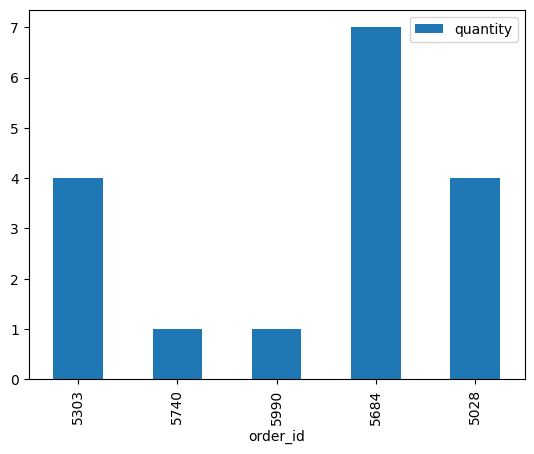

In [328]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df11= data.head(5)
df11.plot(x="order_id",y="quantity",kind ='bar')

<Axes: ylabel='order_id'>

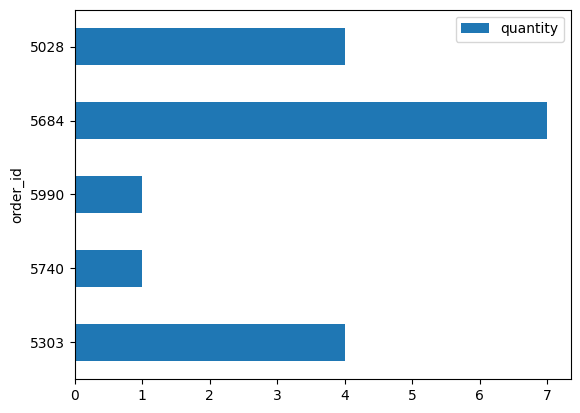

In [329]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df11= data.head(5)
df11.plot(x="order_id",y="quantity",kind ='barh')


<Axes: xlabel='order_id'>

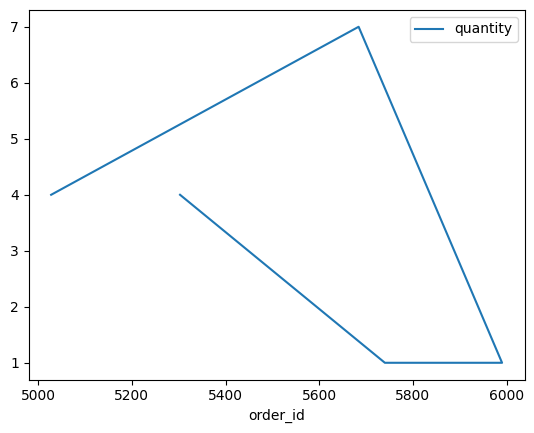

In [335]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df11= data.head(5)
df11.plot(x="order_id",y="quantity",kind ='line')

<Axes: title={'center': 'order_id vs quantity'}, ylabel='quantity'>

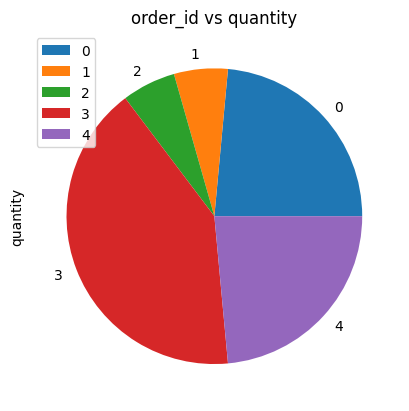

In [333]:
# Pie chart 01

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df11= data.head(5)
df11.plot(x="order_id",y="quantity",kind ='pie',title="order_id vs quantity")

<Axes: title={'center': 'order_id vs quantity'}, xlabel='order_id', ylabel='quantity'>

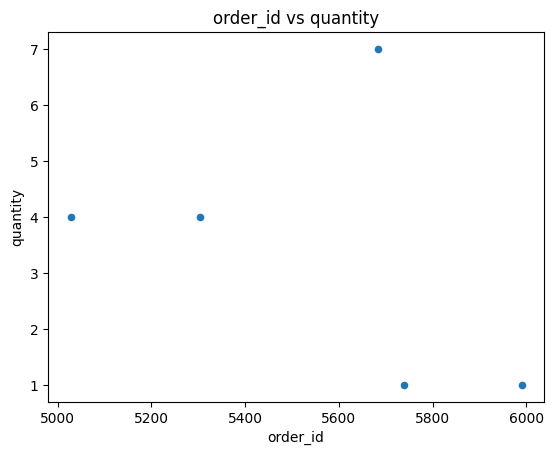

In [337]:
# Pie chart 01

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df11= data.head(5)
df11.plot(x="order_id",y="quantity",kind ='scatter',title="order_id vs quantity")

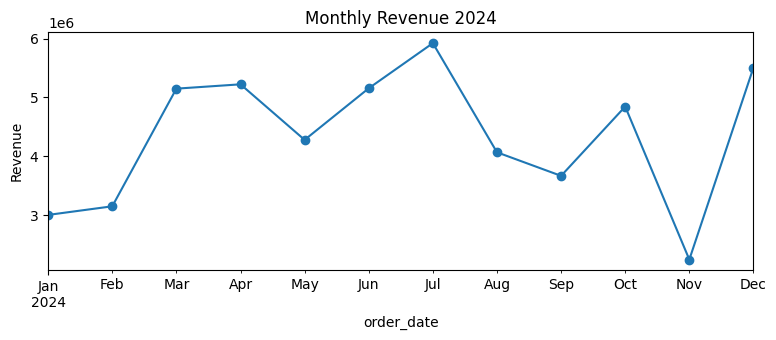

In [132]:
# line chart - monthly revenue
ax = sales.set_index("order_date")["revenue"].resample("ME").sum().plot(
    marker="o", title="Monthly Revenue 2024", figsize=(8, 3.5))
ax.set_ylabel("Revenue")
plt.tight_layout(); plt.savefig("images/monthly_revenue.png", dpi=120); plt.show()

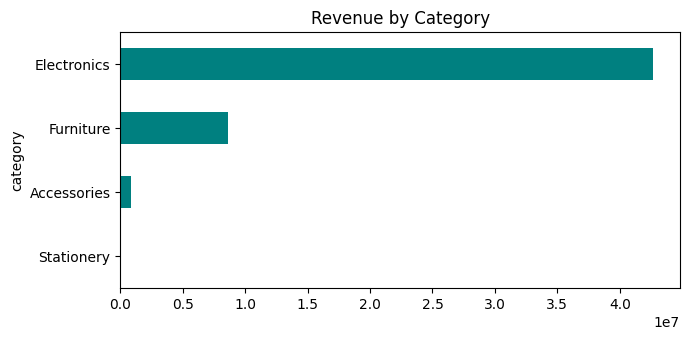

In [133]:
# bar chart - revenue by category
sales.groupby("category")["revenue"].sum().sort_values().plot(
    kind="barh", color="teal", title="Revenue by Category", figsize=(7, 3.5))
plt.tight_layout(); plt.show()

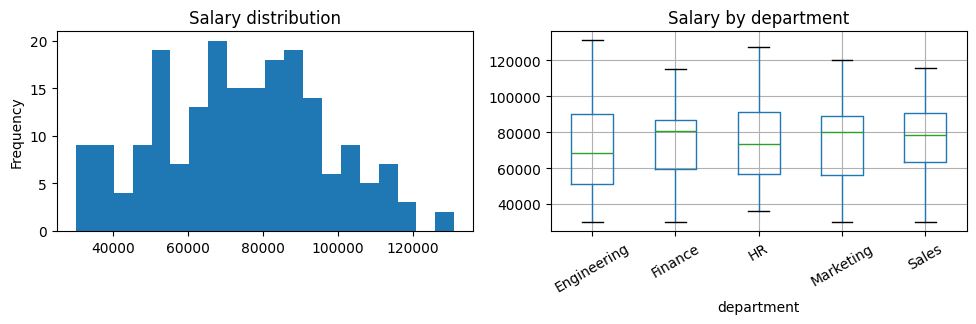

In [134]:
# histogram and box plot
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
emp["salary"].plot(kind="hist", bins=20, ax=axes[0], title="Salary distribution")
emp.boxplot(column="salary", by="department", ax=axes[1], rot=30)
axes[1].set_title("Salary by department"); plt.suptitle("")
plt.tight_layout(); plt.show()

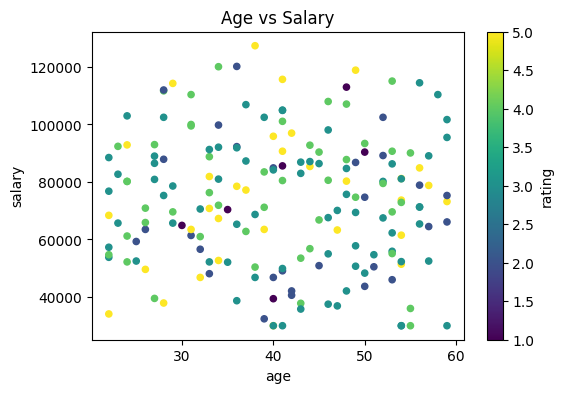

In [136]:
# scatter plot coloured by a variable
emp.plot(kind="scatter", x="age", y="salary", c="rating", cmap="viridis", figsize=(6, 4), title="Age vs Salary")
plt.show()

> For publication-quality charts combine pandas with **Seaborn** or **Plotly** (`pd.options.plotting.backend = "plotly"`).

---
# 21 Performance & Memory Optimisation

`Advanced`

> **Definition.** Pandas is fast when you use vectorised operations, appropriate dtypes and efficient file formats. This lesson shows how to measure and improve speed and memory use.

In [137]:
import time
sales = pd.read_csv("data/sales.csv", parse_dates=["order_date"])

## 1. Vectorise instead of looping

In [138]:
def timeit(f):
    t = time.perf_counter(); r = f(); return r, (time.perf_counter() - t) * 1000

_, t_loop = timeit(lambda: [row.quantity * row.unit_price for row in sales.itertuples()])
_, t_apply = timeit(lambda: sales.apply(lambda r: r["quantity"] * r["unit_price"], axis=1))
_, t_vec = timeit(lambda: sales["quantity"] * sales["unit_price"])
print(f"itertuples {t_loop:.1f} ms | apply {t_apply:.1f} ms | vectorised {t_vec:.3f} ms")

itertuples 4.8 ms | apply 6.4 ms | vectorised 0.277 ms


## 2. Use smaller / categorical dtypes

In [139]:
def mb(d): return d.memory_usage(deep=True).sum() / 1024**2

opt = sales.copy()
for col in ["product", "category", "region"]:
    opt[col] = opt[col].astype("category")
opt["quantity"] = pd.to_numeric(opt["quantity"], downcast="unsigned")
opt["customer_id"] = pd.to_numeric(opt["customer_id"], downcast="unsigned")
opt["unit_price"] = opt["unit_price"].astype("float32")
print(f"before {mb(sales):.3f} MB -> after {mb(opt):.3f} MB")

before 0.089 MB -> after 0.032 MB


## 3. Load only what you need

In [140]:
lean = pd.read_csv("data/sales.csv", usecols=["order_date", "region", "quantity"],
                   dtype={"region": "category", "quantity": "uint8"}, parse_dates=["order_date"])
print(lean.dtypes)

order_date    datetime64[us]
region              category
quantity               uint8
dtype: object


## 4. Efficient file formats and chunking
Parquet/Feather load far faster than CSV and keep dtypes. For files larger than RAM use `chunksize` (see the I/O lesson) or libraries such as **Polars / Dask / DuckDB**.

In [141]:
sales.to_csv("output/s.csv", index=False); sales.to_parquet("output/s.parquet")
_, t_csv = timeit(lambda: pd.read_csv("output/s.csv"))
_, t_pq = timeit(lambda: pd.read_parquet("output/s.parquet"))
print(f"read_csv {t_csv:.1f} ms | read_parquet {t_pq:.1f} ms")

read_csv 2.2 ms | read_parquet 3.1 ms


## 5. Other tips

In [142]:
# query/eval avoid temporary arrays on big frames
big = pd.DataFrame(np.random.default_rng(0).random((200_000, 3)), columns=list("abc"))
r1 = big[(big.a > .5) & (big.b < .5)]
r2 = big.query("a > .5 and b < .5")
print(len(r1) == len(r2))

# avoid growing a DataFrame in a loop -> collect rows in a list, build once
rows = [{"i": i, "sq": i * i} for i in range(1000)]
pd.DataFrame(rows).tail(2)

True


,i,sq
998,998,996004
999,999,998001


### Checklist
- Vectorise; avoid `apply(axis=1)` and Python loops
- `category` for low-cardinality strings, downcast numerics
- `usecols`, `dtype`, `chunksize` when reading
- Parquet instead of CSV for repeated loads
- `groupby(...).agg` with built-in function names (`"sum"`), not lambdas
- Profile first: `%timeit`, `%memit`, `df.info(memory_usage="deep")`

---
# 22 Advanced Techniques: Method Chaining, pipe, Styler, Copy-on-Write

`Advanced`

> **Definition.** Professional pandas code is readable, reproducible and safe. Method chaining, `pipe`, option contexts, styling and understanding Copy-on-Write help you write production-quality analysis code.

In [143]:
sales = pd.read_csv("data/sales.csv", parse_dates=["order_date"])
customers = pd.read_csv("data/customers.csv")

## Method chaining
Each step returns a new object, so a whole pipeline reads top-to-bottom without temporary variables.

In [144]:
report = (
    sales
    .assign(revenue=lambda d: d["quantity"] * d["unit_price"] * (1 - d["discount"].fillna(0)),
            month=lambda d: d["order_date"].dt.to_period("M"))
    .merge(customers, on="customer_id", how="left")
    .query("revenue > 1000")
    .groupby(["segment", "month"], as_index=False)
    .agg(orders=("order_id", "count"), revenue=("revenue", "sum"))
    .sort_values(["segment", "month"])
    .round({"revenue": 0})
)
report.head()

,segment,month,orders,revenue
0,Consumer,2024-01,30,1.68e+06
1,Consumer,2024-02,26,1.13e+06
2,Consumer,2024-03,34,2.41e+06
3,Consumer,2024-04,18,1.90e+06
4,Consumer,2024-05,31,2.07e+06


## `pipe` - plug your own functions into a chain

In [145]:
def add_margin(df, rate=0.2):
    return df.assign(profit=df["revenue"] * rate)

def top_n(df, col, n=3):
    return df.nlargest(n, col)

(report.pipe(add_margin, rate=0.25)
       .pipe(top_n, "profit", n=3))

,segment,month,orders,revenue,profit
6,Consumer,2024-07,30,2.70e+06,674538.25
5,Consumer,2024-06,28,2.65e+06,663629.00
11,Consumer,2024-12,36,2.54e+06,635991.50


## Styling DataFrames (`Styler`) - great for notebooks and Excel export

In [146]:
pt = sales.assign(revenue=sales.quantity * sales.unit_price).pivot_table(
    index="region", columns="category", values="revenue", aggfunc="sum").round(0)

pt.style.format("{:,.0f}").background_gradient(cmap="YlGn", axis=None).highlight_max(axis=0, color="gold")

category,Accessories,Electronics,Furniture,Stationery
region,,,,
East,"259,541","11,140,698","2,858,387","14,389"
North,"230,309","13,106,036","2,198,794","19,245"
South,"216,297","11,011,677","1,760,291","17,380"
West,"197,325","9,443,578","2,209,537","17,058"


## Copy-on-Write (CoW)
In pandas 3 **Copy-on-Write is always on**: any DataFrame/Series derived from another behaves like an independent copy, so modifying it never changes the parent. This removes the infamous `SettingWithCopyWarning`.

```python
subset = df[df["a"] > 1]
subset["b"] = 0            # df is NOT changed - always safe
df.loc[df["a"] > 1, "b"] = 0   # to modify the original, assign through .loc on df itself
```
Avoid `inplace=True` and chained assignment such as `df["a"][0] = 1`.

In [147]:
d = pd.DataFrame({"a": [1, 2, 3], "b": [10, 20, 30]})
view = d[d["a"] > 1]
view.loc[:, "b"] = 0
print(d)          # unchanged
d.loc[d["a"] > 1, "b"] = 0
print(d)          # changed

   a   b
0  1  10
1  2  20
2  3  30


   a   b
0  1  10
1  2   0
2  3   0


## Nested JSON, option contexts, testing

In [148]:
records = [{"id": 1, "user": {"name": "A", "geo": {"city": "Pune"}}, "tags": ["x"]},
           {"id": 2, "user": {"name": "B", "geo": {"city": "Delhi"}}, "tags": []}]
pd.json_normalize(records, sep="_")

,id,tags,user_name,user_geo_city
0,1,[x],A,Pune
1,2,[],B,Delhi


In [149]:
with pd.option_context("display.max_rows", 3, "display.precision", 1):
    print(sales.head(10))

from pandas.testing import assert_frame_equal
assert_frame_equal(pd.DataFrame({"a": [1]}), pd.DataFrame({"a": [1]}))
print("frames equal")

    order_id order_date  customer_id product     category region  quantity  unit_price  discount
0       5303 2024-01-01           44   Phone  Electronics   East         4     32942.7       NaN
..       ...        ...          ...     ...          ...    ...       ...         ...       ...
9       5451 2024-01-05           35     Pen   Stationery   East         5        30.0       0.0

[10 rows x 9 columns]
frames equal


In [150]:
# conditional logic with where/mask, clip, and Series.between inside a chain
(sales["unit_price"].clip(upper=10000).mask(sales["unit_price"] < 100, 100).describe().round(1))

count     1000.0
mean      5322.7
std       4201.4
min        100.0
25%       1651.7
50%       5584.9
75%      10000.0
max      10000.0
Name: unit_price, dtype: float64

---
# 23 Mini Project: End-to-End Sales Analysis

`Project`

> **Definition.** Combine everything you learned: load, clean, enrich, aggregate, visualise and report on a real-style dataset.

## Business questions
1. What is the total and monthly revenue?
2. Which products and regions perform best?
3. Who are the top 5 customers and which segment is most valuable?
4. How does discounting relate to order value?
5. What is the month-over-month growth?

In [151]:
sales = pd.read_csv("data/sales.csv", parse_dates=["order_date"])
customers = pd.read_csv("data/customers.csv", parse_dates=["signup_date"])

df = (sales
      .assign(discount=lambda d: d["discount"].fillna(0),
              revenue=lambda d: d["quantity"] * d["unit_price"] * (1 - d["discount"].fillna(0)),
              month=lambda d: d["order_date"].dt.to_period("M"))
      .merge(customers, on="customer_id", how="left", validate="m:1"))
print(df.shape, "| nulls:", df.isna().sum().sum())
print(f"Total revenue: {df['revenue'].sum():,.0f}")

(1000, 14) | nulls: 0
Total revenue: 52,232,418


In [152]:
# Q1 monthly revenue and growth
m = df.groupby("month")["revenue"].sum().to_frame("revenue")
m["mom_%"] = (m["revenue"].pct_change() * 100).round(1)
m.round(0).head(6)

,revenue,mom_%
month,,
2024-01,3.01e+06,NaN
2024-02,3.15e+06,5.0
2024-03,5.15e+06,63.0
2024-04,5.22e+06,1.0
2024-05,4.28e+06,-18.0
2024-06,5.16e+06,20.0


In [153]:
# Q2 products and regions
print(df.groupby("product")["revenue"].sum().sort_values(ascending=False).round(0))
print(df.pivot_table(index="region", columns="category", values="revenue", aggfunc="sum").round(0))

product
Laptop        2.39e+07
Phone         1.75e+07
Desk          5.99e+06
Chair         2.62e+06
Headphones    1.23e+06
Backpack      8.67e+05
Notebook      5.13e+04
Pen           1.46e+04
Name: revenue, dtype: float64
category  Accessories  Electronics  Furniture  Stationery
region                                                   
East         248862.0     1.07e+07   2.73e+06     14049.0
North        224305.0     1.25e+07   2.09e+06     18463.0
South        204915.0     1.04e+07   1.67e+06     16832.0
West         188999.0     9.13e+06   2.13e+06     16568.0


In [154]:
# Q3 customers and segments
top5 = df.groupby(["customer_id", "customer_name"])["revenue"].sum().nlargest(5).round(0)
print(top5)
print(df.groupby("segment").agg(customers=("customer_id", "nunique"), revenue=("revenue", "sum"),
                                avg_order=("revenue", "mean")).round(0))

customer_id  customer_name
12           Customer_12      1.90e+06
17           Customer_17      1.88e+06
44           Customer_44      1.78e+06
27           Customer_27      1.76e+06
30           Customer_30      1.71e+06
Name: revenue, dtype: float64
                customers   revenue  avg_order
segment                                       
Consumer               23  2.48e+07    55312.0
Corporate              11  1.13e+07    48667.0
Small Business         16  1.62e+07    50506.0


In [155]:
# Q4 discount analysis
df["disc_band"] = pd.cut(df["discount"], [-.01, 0, .1, .2], labels=["None", "Up to 10%", "Up to 20%"])
print(df.groupby("disc_band", observed=True)["revenue"].agg(["count", "mean"]).round(0))

           count     mean
disc_band                
None         554  51706.0
Up to 10%    367  53846.0
Up to 20%     79  48433.0


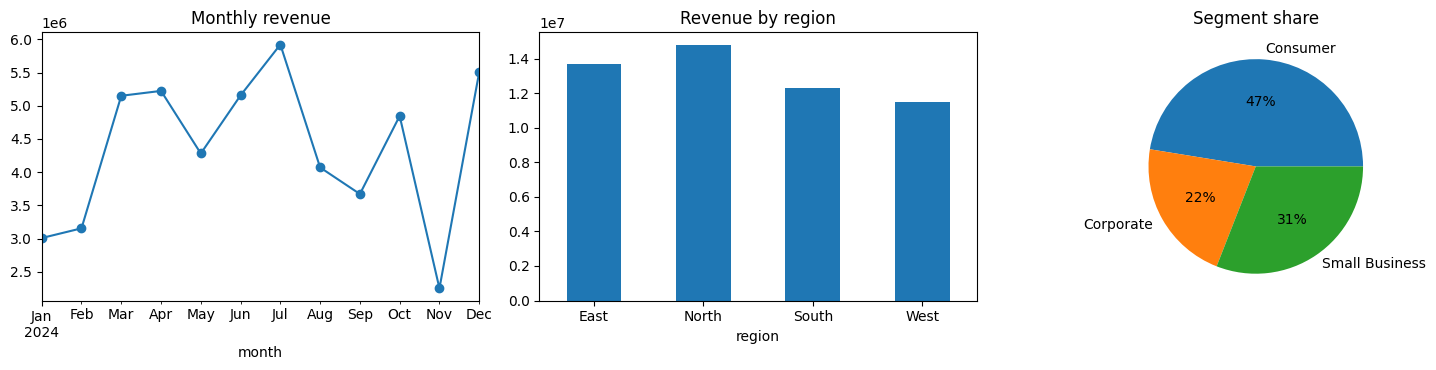

In [156]:
# Q5 final dashboard
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
m["revenue"].plot(ax=ax[0], marker="o", title="Monthly revenue")
df.groupby("region")["revenue"].sum().plot(kind="bar", ax=ax[1], title="Revenue by region", rot=0)
df.groupby("segment")["revenue"].sum().plot(kind="pie", ax=ax[2], autopct="%1.0f%%", ylabel="", title="Segment share")
plt.tight_layout(); plt.savefig("images/dashboard.png", dpi=110); plt.show()

In [157]:
# export results
with pd.ExcelWriter("output/sales_report.xlsx") as w:
    m.to_excel(w, sheet_name="Monthly")
    top5.to_frame().to_excel(w, sheet_name="Top customers")
print("report saved")

report saved


---
# 24 Practice Exercises & Interview Questions

`Project`

> **Definition.** Solve the exercises yourself first, then compare with the solutions below. Interview-style questions cover the most commonly asked pandas concepts.

## Exercises (try before reading the solutions)
1. Load `employees.csv`, remove duplicates and strip names.
2. Find the average salary of each department, sorted descending.
3. Find the 3 highest paid employees of every city.
4. Fill missing ratings with the department median.
5. Create a column `tenure_years` and the count of employees by tenure band.
6. From `sales.csv` find the best-selling product in each region (by revenue).
7. Compute a 7-day rolling average of daily revenue.
8. Which customers have placed no orders?

In [158]:
emp = pd.read_csv("data/employees.csv", parse_dates=["join_date"])
sales = pd.read_csv("data/sales.csv", parse_dates=["order_date"])
customers = pd.read_csv("data/customers.csv")

# 1
emp = emp.drop_duplicates().assign(name=lambda d: d["name"].str.strip())
# 2
print(emp.groupby("department")["salary"].mean().sort_values(ascending=False).round(0))
# 3
print(emp.sort_values("salary", ascending=False).groupby("city").head(3)[["city", "name", "salary"]].sort_values("city").head(6))

department
Sales          76467.0
HR             76315.0
Finance        73906.0
Marketing      73538.0
Engineering    71334.0
Name: salary, dtype: float64
          city         name    salary
177  Bengaluru   Isha Joshi  114300.0
193  Bengaluru  Priya Mehta  113000.0
75   Bengaluru   Ritu Gupta  111700.0
54       Delhi   Pooja Iyer  131100.0
8        Delhi  Arjun Verma  118900.0
53       Delhi   Meera Nair  110400.0


In [159]:
# 4
emp["rating"] = emp["rating"].fillna(emp.groupby("department")["rating"].transform("median"))
print(emp["rating"].isna().sum())
# 5
emp["tenure_years"] = ((pd.Timestamp("2025-01-01") - emp["join_date"]).dt.days / 365.25)
print(pd.cut(emp["tenure_years"], [0, 2, 5, 8, 20]).value_counts().sort_index())

0
tenure_years
(0, 2]     36
(2, 5]     59
(5, 8]     62
(8, 20]    46
Name: count, dtype: int64


In [160]:
# 6
sales["revenue"] = sales["quantity"] * sales["unit_price"]
best = sales.groupby(["region", "product"])["revenue"].sum().reset_index()
print(best.loc[best.groupby("region")["revenue"].idxmax()])
# 7
daily = sales.groupby("order_date")["revenue"].sum()
print(daily.rolling(7).mean().dropna().head(3).round(0))
# 8
print(customers[~customers["customer_id"].isin(sales["customer_id"])])

   region product   revenue
4    East  Laptop  6.02e+06
12  North  Laptop  7.53e+06
20  South  Laptop  6.43e+06
28   West  Laptop  5.23e+06
order_date
2024-01-07     58636.0
2024-01-08     93637.0
2024-01-09    128627.0
Name: revenue, dtype: float64
Empty DataFrame
Columns: [customer_id, customer_name, segment, signup_date]
Index: []


## Interview questions

**1. Series vs DataFrame?** A Series is 1-D labelled; a DataFrame is a 2-D table of Series sharing an index.

**2. `loc` vs `iloc`?** `loc` is label-based and end-inclusive; `iloc` is position-based and end-exclusive.

**3. `merge` vs `join` vs `concat`?** `merge` joins on column keys (SQL-like); `join` is index-based sugar over merge; `concat` stacks objects along an axis.

**4. `apply` vs `map` vs vectorisation?** `map` is element-wise for Series, `apply` runs a function over rows/columns, vectorised operations run in compiled code and are fastest.

**5. How do you handle missing data?** Detect with `isna`, then `dropna`, `fillna` (constant/statistic/group-wise), `interpolate` - after understanding why data is missing.

**6. `transform` vs `agg`?** `agg` reduces each group to one row; `transform` returns a result with the original shape.

**7. `pivot` vs `pivot_table`?** `pivot` only reshapes (needs unique pairs); `pivot_table` aggregates duplicates.

**8. `copy()` vs view, SettingWithCopyWarning?** With Copy-on-Write (default in pandas 3) derived objects are always independent; modify originals through `.loc`.

**9. How would you process a file larger than RAM?** `chunksize`, `usecols`, smaller dtypes, Parquet, or Dask/Polars/DuckDB.

**10. `count` vs `size`?** `count` ignores NaN, `size` counts all rows.

**11. How do you remove duplicates keeping the latest?** `df.sort_values("date").drop_duplicates("id", keep="last")`.

**12. Merge types?** inner, left, right, outer, cross - and use `validate=` and `indicator=True` to catch bad joins.

---
# You made it!

Next steps: practise on real datasets (Kaggle, data.gov, NYC Open Data), read the official docs at <https://pandas.pydata.org/docs/>, then explore **scikit-learn**, **Polars**, **DuckDB** and **Seaborn**.